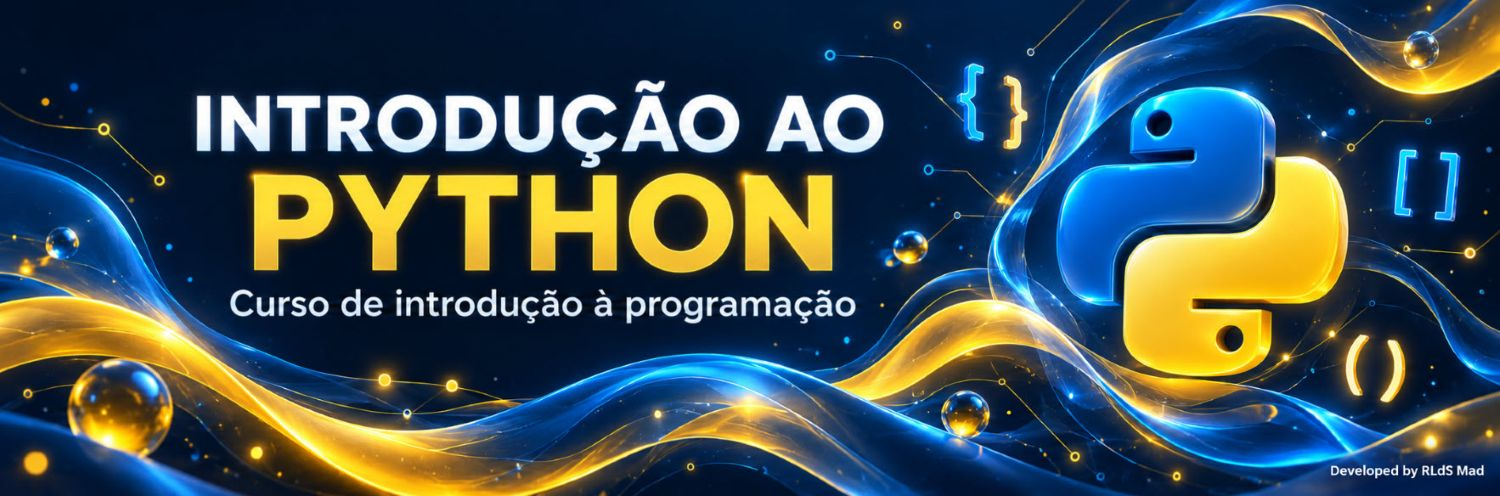

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_1_introducao/RLdS_22_NumPy.ipynb)


# Capítulo 22 – NumPy – dos vetores ao cálculo numérico



## **Revisão matemática · Arrays · Operações · Aplicações · Álgebra linear (opcional)**

Este módulo apresenta uma progressão dos fundamentos matemáticos à utilização prática de NumPy.

**Pré-requisitos:** variáveis, listas, dicionários, condições, ciclos e funções de Python. Não precisas de conhecer Pandas. 

**Duração sugerida:** 12–18 horas, distribuídas por sessões; a secção opcional pode exigir 3–4 horas adicionais.

**Objetivos:** interpretar formas e eixos; criar e selecionar arrays; distinguir operações elemento a elemento e matriciais; aplicar broadcasting; detetar partilha de memória; preparar dados numéricos; resolver problemas com verificação dos resultados.

### Como estudar
- Executa as células por ordem com **Shift + Enter**, em Jupyter, VS Code ou Colab.
- Antes de executar uma operação, prevê os valores e a **forma do resultado**.
- Consulta a interpretação após cada exemplo e experimenta outras entradas.
- As células dos exercícios são espaços de trabalho facultativos; as soluções no fim são executáveis sem preencher esses espaços.
- No final, reinicia o kernel e executa tudo para confirmar a reprodução.

Os exemplos não precisam de Internet depois da instalação. Os dados são gerados no próprio notebook. As figuras são incorporadas nas saídas, sem depender de uma pasta externa de imagens. As células de exportação criam ou substituem ficheiros de demonstração em `numpy_tutorial_lab`; guarda ficheiros teus noutro local. No Colab, descarrega os resultados antes de terminar a sessão.

### Percurso
**Preparação:** ambiente e convenções.

**Parte I - Revisão matemática aplicada:** escalares, vetores, matrizes, operações, produto escalar, produto matricial, transposta, norma e distância.

**Parte II - NumPy:** `1.` Introdução; `2.` Listas e arrays; `3.` Criação; `4.` Atributos; `5.` Tipos; `6.` Indexação; `7.` Máscaras; `8.` Cópias e vistas; `9.` Reorganização; `10.` Junção e divisão; `11.` Broadcasting; `12.` Eixos e agregações; `13.` Ordenação; `14.` Aleatoriedade.

**Parte III - Aplicações:** `15.` Cálculo numérico; `16.` Álgebra linear aplicada; `17.` Preparação de dados; `18.` Distâncias e similaridade; `19.` Desempenho; `20.` Ficheiros; `21.` Miniprojeto; `22.` Consulta e consolidação.

**Parte IV - Opcional:** `23.` Determinante, posto, inversa, valores próprios, sistemas e condicionamento.

**Parte V:** Soluções dos 20 exercícios, verificações finais e referências.

## Preparação do ambiente
Descomenta a linha de instalação apenas se necessário. `%pip` instala no ambiente do kernel; reinicia o kernel depois de instalar. As dependências de execução são NumPy e Matplotlib. A versão exata utilizada fica registada na célula seguinte.

Os exemplos usam `ndarray`, não a antiga classe `np.matrix`. O operador `*` mantém assim o significado de multiplicação elemento a elemento.

In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install numpy matplotlib

In [2]:
import sys
import json
import platform
import timeit
import warnings
from pathlib import Path
from io import BytesIO, StringIO
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

np.set_printoptions(precision=4, suppress=True)
PASTA = Path.cwd() / "numpy_tutorial_lab"
PASTA.mkdir(exist_ok=True)
VERSOES = {"python": platform.python_version(), "numpy": np.__version__}
print(VERSOES)
print("Pasta dos ficheiros de demonstração:", PASTA)

def mostrar_figura(fig):
    """Incorporar a figura no notebook, sem ligação a um ficheiro externo."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

{'python': '3.12.3', 'numpy': '2.5.4'}
Pasta dos ficheiros de demonstração: /content/numpy_tutorial_lab


# Parte I – Revisão matemática aplicada
## M1. Escalares, vetores e matrizes
Um **escalar** é um único número; um **vetor** reúne componentes ordenadas; uma **matriz** organiza elementos em linhas e colunas.

$$s=3,\qquad u=\begin{bmatrix}2\\1\end{bmatrix},\qquad A=\begin{bmatrix}1&2\\3&4\end{bmatrix}.$$

Na matriz, $a_{ij}$ identifica o elemento da linha $i$ e coluna $j$. Na notação matemática é frequente começar em 1; em Python os índices começam em **0**.

| Matemática | Significado | Representação NumPy |
|---|---|---|
| Escalar | Um número | `np.array(3)` tem forma `()` |
| Vetor | Duas componentes | `np.array([2, 1])` tem forma `(2,)` |
| Matriz | Duas linhas, duas colunas | Forma `(2, 2)` |

Vamos já confirmar estas representações; os detalhes de criação serão desenvolvidos na **`Parte II`**.

In [3]:
escalar = np.array(3)
vetor = np.array([2, 1])
matriz = np.array([[1, 2], [3, 4]])
for nome, arr in [("escalar", escalar), ("vetor", vetor), ("matriz", matriz)]:
    print(nome, "=", arr, "| shape:", arr.shape, "| ndim:", arr.ndim)

escalar = 3 | shape: () | ndim: 0
vetor = [2 1] | shape: (2,) | ndim: 1
matriz = [[1 2]
 [3 4]] | shape: (2, 2) | ndim: 2


### M2. Somar, subtrair e multiplicar por um escalar

Para vetores com o mesmo número de componentes, as operações fazem-se componente a componente:

$$[2,1]+[-1,3]=[1,4],\qquad 3[2,1]=[6,3].$$

O mesmo princípio aplica-se a matrizes de igual dimensão. NumPy também permite algumas operações com formas diferentes, através de broadcasting, que será estudado depois.

In [4]:
u = np.array([2, 1])
v = np.array([-1, 3])
print("u + v =", u + v)
print("u - v =", u - v)
print("3u =", 3 * u)
A = np.array([[1, 2], [3, 4]])
B = np.array([[2, 0], [1, 5]])
print("A + B =\n", A + B)

u + v = [1 4]
u - v = [ 3 -2]
3u = [6 3]
A + B =
 [[3 2]
 [4 9]]


**Interpretação:** A soma de vetores conserva duas componentes. A soma de matrizes conserva duas linhas e duas colunas.

### M3. Produto escalar e produto elemento a elemento

São operações diferentes:

$$u\odot v=[2(-1),1(3)]=[-2,3],\qquad u\cdot v=2(-1)+1(3)=1.$$

O primeiro resultado é um vetor; o segundo é um escalar. Para estes vetores reais 1D, `u @ v` calcula o produto escalar.

In [5]:
print("Elemento a elemento:", u * v)
print("Produto escalar:", u @ v)
print("Soma dos produtos:", np.sum(u * v))
assert u @ v == 1

Elemento a elemento: [-2  3]
Produto escalar: 1
Soma dos produtos: 1


### M4. Produto matriz-vetor e matriz-matriz

No produto matricial, as dimensões interiores têm de coincidir:

$$(m\times n)(n\times p)\longrightarrow(m\times p).$$

Com $A=\begin{bmatrix}1&2\\3&4\end{bmatrix}$ e $x=\begin{bmatrix}2\\-1\end{bmatrix}$:

$$Ax=\begin{bmatrix}1(2)+2(-1)\\3(2)+4(-1)\end{bmatrix}=\begin{bmatrix}0\\2\end{bmatrix}.$$

Cada entrada de $AB$ é o produto escalar de uma linha de $A$ com uma coluna de $B$.

In [6]:
x = np.array([2, -1])
print("A @ x =", A @ x)
print("A @ B =\n", A @ B)
print("A * B =\n", A * B)
print("B @ A =\n", B @ A)
print("Formas:", A.shape, x.shape, (A @ x).shape)
assert np.array_equal(A @ B, np.array([[4, 10], [10, 20]]))

A @ x = [0 2]
A @ B =
 [[ 4 10]
 [10 20]]
A * B =
 [[ 2  0]
 [ 3 20]]
B @ A =
 [[ 2  4]
 [16 22]]
Formas: (2, 2) (2,) (2,)


**Interpretação:** Em geral, `A @ B` é diferente de `B @ A`. O resultado de matriz 2D vezes vetor 1D é um vetor 1D. As regras de broadcasting de `*` não substituem as regras do produto matricial.

### M5. Transposta e orientação de vetores

A transposta troca linhas e colunas: $(A^T)_{ij}=A_{ji}$. Um array 1D de NumPy **não tem orientação de linha ou coluna**; `.T` não muda a sua forma. Para a tornar explícita, usamos duas dimensões.

In [7]:
w = np.array([4, 7, 9])
w_linha = w.reshape(1, -1)
w_coluna = w.reshape(-1, 1)
print("1D:", w.shape, "| transposta 1D:", w.T.shape)
print("Linha:", w_linha.shape, "| coluna:", w_coluna.shape)
print("A.T =\n", A.T)
print("Linha @ coluna:", w_linha @ w_coluna)
print("Coluna @ linha:\n", w_coluna @ w_linha)

1D: (3,) | transposta 1D: (3,)
Linha: (1, 3) | coluna: (3, 1)
A.T =
 [[1 3]
 [2 4]]
Linha @ coluna: [[146]]
Coluna @ linha:
 [[16 28 36]
 [28 49 63]
 [36 63 81]]


**Interpretação:** `(3,)`, `(1, 3)` e `(3, 1)` não são formas equivalentes em todas as operações. Linha vezes coluna produz uma matriz `(1, 1)`; coluna vezes linha produz uma matriz `(3, 3)`.

### M6. Norma e distância euclidiana

A norma euclidiana mede o comprimento de um vetor:

$$\lVert u\rVert_2=\sqrt{u_1^2+u_2^2},\qquad d(u,v)=\lVert u-v\rVert_2.$$

Para $u=[2,1]$, a norma é $\sqrt5$. Para $u-v=[3,-2]$, a distância é $\sqrt{13}$.

Norma de u: 2.23606797749979
Distância u-v: 3.605551275463989


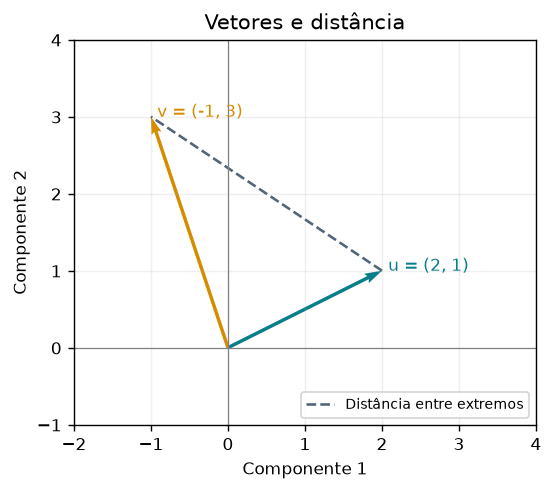

In [8]:
print("Norma de u:", np.linalg.norm(u))
print("Distância u-v:", np.linalg.norm(u-v))
assert np.isclose(np.linalg.norm(u-v), np.sqrt(13))
fig, ax = plt.subplots(figsize=(5, 4))
for vv, cor, nome in [(u, "#087e8b", "u = (2, 1)"), (v, "#d58c00", "v = (-1, 3)")]:
    ax.quiver(0, 0, vv[0], vv[1], angles="xy", scale_units="xy", scale=1, color=cor)
    ax.text(vv[0]+0.08, vv[1], nome, color=cor)
ax.plot([u[0], v[0]], [u[1], v[1]], "--", color="#526579", label="Distância entre extremos")
ax.set(xlim=(-2, 4), ylim=(-1, 4), xlabel="Componente 1", ylabel="Componente 2", title="Vetores e distância")
ax.axhline(0, color="grey", lw=0.7); ax.axvline(0, color="grey", lw=0.7)
ax.set_aspect("equal"); ax.grid(alpha=0.2); ax.legend(loc="lower right", fontsize=8)
mostrar_figura(fig)

### Exercício 1

Para `p = [3, -2]` e `q = [1, 4]`, calcula à mão e depois em NumPy: soma, produto elemento a elemento, produto escalar e distância. Prevê se cada resultado é escalar ou vetor.

Resolve antes de consultar a solução comentada na parte final.

In [9]:
# Exercício 1 – escreve a tua resolução aqui.


# Parte II – Fundamentos de NumPy
## 1. O que é NumPy?
NumPy fornece o objeto `ndarray` e operações para cálculo numérico com arrays. Pandas e muitas bibliotecas de ciência de dados trabalham com arrays ou estruturas relacionadas. NumPy é especialmente útil quando os dados têm organização numérica regular.

Um array pode ter zero, uma, duas ou mais dimensões. Em aprendizagem automática, é comum organizar uma matriz com **observações nas linhas e variáveis nas colunas**. Esta convenção tem de ser documentada: NumPy não conhece o significado dos eixos.

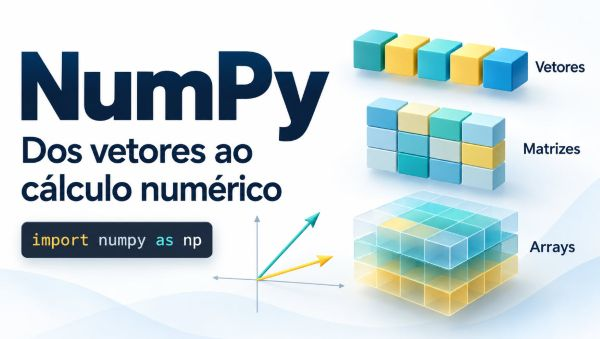

### 2. Listas Python e arrays

Uma lista pode conter objetos de tipos diferentes. Um array NumPy tem um único `dtype`; pode também ter tipo `object`, mas isso perde muitas das vantagens de um array numérico homogéneo.

In [10]:
lista = [2, 5, 8]
arr = np.array(lista)
print("Lista * 2:", lista * 2)
print("Array * 2:", arr * 2)
print("Lista + lista:", lista + lista)
print("Array + array:", arr + arr)
print("Conversão comum:", np.array([1, 2.5, 3]).dtype)

Lista * 2: [2, 5, 8, 2, 5, 8]
Array * 2: [ 4 10 16]
Lista + lista: [2, 5, 8, 2, 5, 8]
Array + array: [ 4 10 16]
Conversão comum: float64


**Interpretação:** A lista é repetida ou concatenada. Os arrays somam e multiplicam os números elemento a elemento. Misturar inteiros e decimais leva, neste caso, a um tipo decimal comum.

### 3. Criar arrays

`arange` usa início incluído e limite final excluído. `linspace` escolhe o número de pontos e inclui o limite final por defeito. Para intervalos decimais com número exato de pontos, `linspace` costuma ser mais claro.

In [11]:
print("array:", np.array([4, 8, 12]))
print("arange:", np.arange(2, 15, 3))
print("linspace:", np.linspace(0, 1, 5))
print("zeros:\n", np.zeros((2, 3)))
print("ones:\n", np.ones((2, 2)))
print("full:\n", np.full((2, 3), 7))
print("identidade:\n", np.eye(3))
print("zeros_like:", np.zeros_like(arr))

array: [ 4  8 12]
arange: [ 2  5  8 11 14]
linspace: [0.   0.25 0.5  0.75 1.  ]
zeros:
 [[0. 0. 0.]
 [0. 0. 0.]]
ones:
 [[1. 1.]
 [1. 1.]]
full:
 [[7 7 7]
 [7 7 7]]
identidade:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
zeros_like: [0 0 0]


**Interpretação:** `zeros` e `ones` criam floats por defeito; podes definir `dtype`. `eye` produz uns na diagonal principal e zeros fora dela. `empty` reserva memória sem inicializar os valores: só deve ser lido depois de preencher todos os elementos.

### 4. Atributos e arrays 3D

A forma enumera o tamanho de cada eixo. O produto dos tamanhos dos eixos dá o número de elementos. `itemsize` é o número de bytes de um elemento; `nbytes` é o espaço lógico dos elementos, sem contabilizar todos os metadados do objeto.

In [12]:
cubo = np.arange(24, dtype=np.int32).reshape(2, 3, 4)
print(cubo)
for atributo in ["shape", "ndim", "size", "dtype", "itemsize", "nbytes"]:
    print(atributo, "=", getattr(cubo, atributo))
assert cubo.size == 2 * 3 * 4
assert cubo.nbytes == cubo.size * cubo.itemsize

[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]
shape = (2, 3, 4)
ndim = 3
size = 24
dtype = int32
itemsize = 4
nbytes = 96


**Interpretação:** A forma `(2, 3, 4)` pode representar dois grupos de três linhas e quatro colunas. Os nomes “grupo”, “linha” e “coluna” são uma interpretação nossa, não uma propriedade atribuída por NumPy.

### Exercício 2

Cria um array `int32` com os valores de 10 a 45, inclusive, organizado em `(3, 4, 3)`. Mostra forma, dimensões, número de elementos, bytes por elemento e bytes totais.

Resolve antes de consultar a solução comentada na parte final.

In [13]:
# Exercício 2 – escreve a tua resolução aqui.


### 5. Tipos, conversão e limites

Escolher um tipo menor pode poupar memória, mas limita os valores representáveis. `astype` converte e, ao passar de float para inteiro, trunca em direção a zero: não arredonda para o inteiro mais próximo.

In [14]:
decimais = np.array([1.9, -2.9, 3.1])
print("Truncagem:", decimais.astype(np.int32))
print("Arredondamento:", np.rint(decimais))
print("Limites int8:", np.iinfo(np.int8))
print("Precisão float32:", np.finfo(np.float32).eps)
print("Precisão float64:", np.finfo(np.float64).eps)
pequenos = np.array([120], dtype=np.int8)
print("Soma em int8:", pequenos + np.array([20], dtype=np.int8))
print("Soma após converter:", pequenos.astype(np.int64) + 20)

Truncagem: [ 1 -2  3]
Arredondamento: [ 2. -3.  3.]
Limites int8: Machine parameters for int8
---------------------------------------------------------------
min = -128
max = 127
---------------------------------------------------------------

Precisão float32: 1.1920929e-07
Precisão float64: 2.220446049250313e-16
Soma em int8: [-116]
Soma após converter: [140]


**Interpretação:** O resultado em `int8` transborda e não é 140. Antes de otimizar tipos, confirma os limites de dados e cálculos intermédios. A precisão de ponto flutuante também é finita.

### 6. Indexação e slicing 1D

Usa `inicio:fim:passo`; o limite final é excluído. Índices negativos contam a partir do fim. O passo negativo permite inverter a ordem.

In [15]:
sequencia = np.array([12, 18, 24, 30, 36, 42, 48])
print("Primeiro / último:", sequencia[0], sequencia[-1])
print("Índices 1 a 3:", sequencia[1:4])
print("De dois em dois:", sequencia[::2])
print("Invertido:", sequencia[::-1])
print("Sem extremos:", sequencia[1:-1])

Primeiro / último: 12 48
Índices 1 a 3: [18 24 30]
De dois em dois: [12 24 36 48]
Invertido: [48 42 36 30 24 18 12]
Sem extremos: [18 24 30 36 42]


### 6.1 Seleção 2D e preservação de dimensões

A vírgula separa eixos. Selecionar um inteiro remove esse eixo; selecionar um intervalo preserva-o.

In [16]:
grelha = np.arange(10, 30).reshape(4, 5)
print("Grelha:\n", grelha)
print("Terceira linha:", grelha[2, :], grelha[2, :].shape)
print("Terceira linha como matriz:", grelha[2:3, :], grelha[2:3, :].shape)
print("Segunda coluna:", grelha[:, 1])
print("Segunda coluna 2D:\n", grelha[:, 1:2])
print("Bloco:\n", grelha[1:3, 2:5])
print("Elemento linha 2, coluna 4 (índices 1,3):", grelha[1, 3])

Grelha:
 [[10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]
 [25 26 27 28 29]]
Terceira linha: [20 21 22 23 24] (5,)
Terceira linha como matriz: [[20 21 22 23 24]] (1, 5)
Segunda coluna: [11 16 21 26]
Segunda coluna 2D:
 [[11]
 [16]
 [21]
 [26]]
Bloco:
 [[17 18 19]
 [22 23 24]]
Elemento linha 2, coluna 4 (índices 1,3): 18


**Interpretação:** A diferença entre `(5,)` e `(1, 5)` pode mudar uma operação posterior. Selecionar uma coluna com `[:, 1:2]` preserva a forma `(4, 1)`.

### 6.2 Seleção 3D

Para interpretar uma seleção, escreve o significado e o tamanho de cada eixo antes de calcular.

In [17]:
lotes = np.arange(60).reshape(3, 4, 5)
print("Forma inicial:", lotes.shape)
print("Segundo lote:\n", lotes[1])
print("Últimas duas linhas de todos os lotes:", lotes[:, -2:, :].shape)
print("Uma posição em cada lote:", lotes[:, 1, 2])
assert lotes[:, -2:, :].shape == (3, 2, 5)

Forma inicial: (3, 4, 5)
Segundo lote:
 [[20 21 22 23 24]
 [25 26 27 28 29]
 [30 31 32 33 34]
 [35 36 37 38 39]]
Últimas duas linhas de todos os lotes: (3, 2, 5)
Uma posição em cada lote: [ 7 27 47]


### Exercício 3

Cria uma grelha `(5, 6)` com valores de 0 a 29. Extrai o bloco das linhas de índices 1 a 3 e colunas de índices 2 a 4; seleciona a última coluna mantendo duas dimensões; inverte a ordem das linhas.

Resolve antes de consultar a solução comentada na parte final.

In [18]:
# Exercício 3 – escreve a tua resolução aqui.


### 7. Máscaras booleanas e atualização

As comparações devolvem booleanos. Usa `&`, `|` e `~` com parênteses; não uses `and` e `or` para combinar arrays de condições.

In [19]:
leituras = np.array([-3., 4., 8., 12., -1., 6.])
mascara = (leituras >= 0) & (leituras <= 10)
print("Máscara:", mascara)
print("Selecionadas:", leituras[mascara])
print("Índices dos negativos:", np.flatnonzero(leituras < 0))
limpas = leituras.copy()
limpas[limpas < 0] = 0
print("Cópia corrigida:", limpas)
print("Origem:", leituras)
print("Clip 0–10:", np.clip(leituras, 0, 10))

Máscara: [False  True  True False False  True]
Selecionadas: [4. 8. 6.]
Índices dos negativos: [0 4]
Cópia corrigida: [ 0.  4.  8. 12.  0.  6.]
Origem: [-3.  4.  8. 12. -1.  6.]
Clip 0–10: [ 0.  4.  8. 10.  0.  6.]


**Interpretação:** `clip` impõe limites numéricos; isso não justifica automaticamente a correção. O domínio e as regras de tratamento têm de fazer sentido para a origem dos dados.

### 7.1 where, argwhere e índices avançados

`where(condicao, a, b)` escolhe valores; `argwhere` devolve coordenadas. Selecionar listas de linhas e colunas simultaneamente pode escolher pares de posições, em vez de um bloco.

In [20]:
M = np.array([[4, 1, 9], [2, 8, 3], [7, 0, 6]])
print("Rotular >= 6:\n", np.where(M >= 6, "alto", "baixo"))
print("Coordenadas >= 6:\n", np.argwhere(M >= 6))
print("Pares (0,1), (2,2):", M[[0, 2], [1, 2]])
print("Produto cartesiano de linhas e colunas:\n", M[np.ix_([0, 2], [1, 2])])
print("Máscara 2D devolve 1D:", M[M >= 6], M[M >= 6].shape)

Rotular >= 6:
 [['baixo' 'baixo' 'alto']
 ['baixo' 'alto' 'baixo']
 ['alto' 'baixo' 'alto']]
Coordenadas >= 6:
 [[0 2]
 [1 1]
 [2 0]
 [2 2]]
Pares (0,1), (2,2): [1 6]
Produto cartesiano de linhas e colunas:
 [[1 9]
 [0 6]]
Máscara 2D devolve 1D: [9 8 7 6] (4,)


### Exercício 4

Numa matriz `[[2, -3, 8], [11, 4, -1]]`, conta os negativos, obtém as suas coordenadas e cria uma cópia com valores limitados ao intervalo [0, 10]. Confirma que a origem não mudou.

Resolve antes de consultar a solução comentada na parte final.

In [21]:
# Exercício 4 – escreve a tua resolução aqui.


### 8. Cópias, vistas e partilha de memória

Atribuir outro nome não copia os dados. Slicing básico cria vistas; a indexação avançada e booleana cria cópias na seleção. `.copy()` pede uma cópia explícita.

In [22]:
origem = np.arange(8)
alias = origem
vista = origem[2:6]
copia = origem[2:6].copy()
avancada = origem[[2, 3, 4, 5]]
print("Mesmo objeto:", alias is origem)
print("Vista partilha memória:", np.shares_memory(origem, vista))
print("Seleção avançada partilha memória:", np.shares_memory(origem, avancada))
vista[0] = 99
copia[1] = -5
print("Origem alterada pela vista:", origem)
print("Cópia independente:", copia)
assert origem[2] == 99 and origem[3] == 3

Mesmo objeto: True
Vista partilha memória: True
Seleção avançada partilha memória: False
Origem alterada pela vista: [ 0  1 99  3  4  5  6  7]
Cópia independente: [ 2 -5  4  5]


**Interpretação:** `origem[indices] = valores` atualiza diretamente a origem, apesar de `selecionados = origem[indices]` criar uma cópia na leitura. Distingue selecionar uma tabela temporária de atribuir através de um índice.

### 8.1 Layout e continuidade

Um array transposto pode partilhar memória e não ser contíguo na ordem C. As strides indicam quantos bytes se avançam por eixo. `reshape` cria uma vista quando possível e uma cópia quando necessário; não assumas qual ocorreu sem verificar.

In [23]:
base = np.arange(12, dtype=np.int64).reshape(3, 4)
transposta = base.T
print("Strides base:", base.strides, "| transposta:", transposta.strides)
print("Base C-contígua:", base.flags["C_CONTIGUOUS"])
print("Transposta C-contígua:", transposta.flags["C_CONTIGUOUS"])
reorganizada = transposta.reshape(-1)
print("Reorganizada partilha dados:", np.shares_memory(base, reorganizada))
contigua = np.ascontiguousarray(transposta)
print("Cópia contígua:", contigua.flags["C_CONTIGUOUS"])

Strides base: (32, 8) | transposta: (8, 32)
Base C-contígua: True
Transposta C-contígua: False
Reorganizada partilha dados: False
Cópia contígua: True


### Exercício 5

Cria uma vista das três primeiras posições de um array e altera-a. Depois repete com `.copy()`. Usa `np.shares_memory` e explica qual das alterações afeta a origem.

Resolve antes de consultar a solução comentada na parte final.

In [24]:
# Exercício 5 – escreve a tua resolução aqui.


### 9. reshape, ravel, flatten e novos eixos

O número de elementos tem de ser preservado. `-1` infere uma dimensão, mas só pode aparecer uma vez. `ravel` devolve uma vista quando possível; `flatten` devolve uma cópia.

In [25]:
serie = np.arange(18)
reforma = serie.reshape(3, -1)
print("Forma:", reforma.shape)
print("Novo eixo coluna:", serie[:, None].shape)
print("Novo eixo linha:", serie[None, :].shape)
print("ravel partilha:", np.shares_memory(reforma, reforma.ravel()))
print("flatten partilha:", np.shares_memory(reforma, reforma.flatten()))
print("Squeeze:", np.zeros((1, 3, 1)).squeeze().shape)
try:
    serie.reshape(4, 5)
except ValueError as erro:
    print("Falha esperada:", erro)

Forma: (3, 6)
Novo eixo coluna: (18, 1)
Novo eixo linha: (1, 18)
ravel partilha: True
flatten partilha: False
Squeeze: (3,)
Falha esperada: cannot reshape array of size 18 into shape (4,5)


### 9.1 Transpor arrays com vários eixos

Em 3D, `.T` inverte a ordem de todos os eixos. Para uma intenção diferente, indica a permutação com `transpose` ou usa `swapaxes`.

In [26]:
tensor = np.arange(40).reshape(2, 4, 5)
permutado = tensor.transpose(0, 2, 1)
print("Original:", tensor.shape)
print(".T:", tensor.T.shape)
print("transpose(0,2,1):", permutado.shape)
restaurado = permutado.transpose(0, 2, 1)
assert np.array_equal(restaurado, tensor)
assert np.array_equal(tensor.swapaxes(1, 2), permutado)

Original: (2, 4, 5)
.T: (5, 4, 2)
transpose(0,2,1): (2, 5, 4)


### 10. Juntar, empilhar e dividir

`concatenate` junta num eixo existente; `stack` cria um eixo novo. Nos exemplos 2D, `vstack` junta linhas e `hstack` junta colunas. Em 1D, `hstack` concatena sequências; não transforma automaticamente vetores em colunas.

In [27]:
bloco_a = np.array([[2, 4], [6, 8]])
bloco_b = np.array([[1, 3], [5, 7]])
print("Concatenar linhas:\n", np.concatenate([bloco_a, bloco_b], axis=0))
print("Concatenar colunas:\n", np.concatenate([bloco_a, bloco_b], axis=1))
print("Empilhar num novo eixo:", np.stack([bloco_a, bloco_b], axis=0).shape)
print("vstack:", np.vstack([bloco_a, bloco_b]).shape)
print("hstack:", np.hstack([bloco_a, bloco_b]).shape)
print("Dois vetores como colunas:\n", np.column_stack([np.arange(3), np.arange(3)+10]))
print("Divisão desigual:", np.array_split(np.arange(8), 3))

Concatenar linhas:
 [[2 4]
 [6 8]
 [1 3]
 [5 7]]
Concatenar colunas:
 [[2 4 1 3]
 [6 8 5 7]]
Empilhar num novo eixo: (2, 2, 2)
vstack: (4, 2)
hstack: (2, 4)
Dois vetores como colunas:
 [[ 0 10]
 [ 1 11]
 [ 2 12]]
Divisão desigual: [array([0, 1, 2]), array([3, 4, 5]), array([6, 7])]


### Exercício 6

Cria dois arrays `(2, 4)`. Obtém resultados com formas `(4, 4)`, `(2, 8)` e `(2, 2, 4)` usando concatenação ou empilhamento. Explica qual operação criou um eixo.

Resolve antes de consultar a solução comentada na parte final.

In [28]:
# Exercício 6 – escreve a tua resolução aqui.


## 11. Broadcasting: prever compatibilidade
NumPy compara as formas **da direita para a esquerda**. Em cada posição, os tamanhos têm de ser iguais ou um deles tem de ser 1. Dimensões em falta são tratadas como 1.

| Formas | Compatibilidade | Resultado |
|---|---|---|
| `(3, 4)` e `(4,)` | Sim | `(3, 4)` |
| `(3, 4)` e `(3, 1)` | Sim | `(3, 4)` |
| `(3, 4)` e `(3,)` | Não: 4 e 3 diferem | Erro |
| `(3, 1)` e `(1, 4)` | Sim | `(3, 4)` |

A expansão é conceptual: não é necessário copiar fisicamente o array pequeno para cada posição. Porém, o **resultado e os temporários** podem consumir muita memória.

In [29]:
dados_broadcast = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])
por_coluna = np.array([10, 20, 30, 40])
por_linha = np.array([100, 200, 300])[:, None]
print("Somar um valor por coluna:\n", dados_broadcast + por_coluna)
print("Somar um valor por linha:\n", dados_broadcast + por_linha)
print("Forma prevista:", np.broadcast_shapes((3, 1), (1, 4)))
try:
    dados_broadcast + np.array([10, 20, 30])
except ValueError as erro:
    print("Incompatibilidade esperada:", erro)

Somar um valor por coluna:
 [[11 22 33 44]
 [15 26 37 48]
 [19 30 41 52]]
Somar um valor por linha:
 [[101 102 103 104]
 [205 206 207 208]
 [309 310 311 312]]
Forma prevista: (3, 4)
Incompatibilidade esperada: operands could not be broadcast together with shapes (3,4) (3,) 


### Exercício 7

Para uma matriz `(4, 3)`, soma um vetor de três valores a todas as linhas e multiplica cada linha por um dos fatores `[1, 2, 3, 4]`. Mostra as formas e usa um eixo novo onde necessário.

Resolve antes de consultar a solução comentada na parte final.

In [30]:
# Exercício 7 – escreve a tua resolução aqui.


## 12. Eixos e agregações sem ambiguidades
Uma redução ao longo de `axis=k` agrega as posições desse eixo. Sem `keepdims`, esse eixo desaparece do resultado.

Para uma matriz de **3 observações × 4 variáveis**:

| Operação | Eixo reduzido | Resultado | Significado |
|---|---|---|---|
| `sum(axis=0)` | Observações | `(4,)` | Um total por variável |
| `sum(axis=1)` | Variáveis | `(3,)` | Um total por observação |
| `sum()` | Todos | Escalar | Total global |
| `sum(axis=0, keepdims=True)` | Observações, preservando o eixo | `(1, 4)` | Totais prontos para broadcasting |

Não memorizes apenas “por linhas” ou “por colunas”: pergunta **qual eixo está a desaparecer**.

In [31]:
medidas = np.array([[2., 4., 6., 8.], [3., 6., 9., 12.], [5., 10., 15., 20.]])
for eixo in [0, 1]:
    resultado = medidas.sum(axis=eixo)
    print("axis =", eixo, "| resultado:", resultado, "| forma:", resultado.shape)
print("Global:", medidas.sum())
print("Média por variável:", medidas.mean(axis=0, keepdims=True))
print("Mínimo por observação:", medidas.min(axis=1))
print("Máximo por variável:", medidas.max(axis=0))
print("Posição do máximo por variável:", medidas.argmax(axis=0))
print("Todos positivos?", np.all(medidas > 0))
print("Algum superior a 18?", np.any(medidas > 18))

axis = 0 | resultado: [10. 20. 30. 40.] | forma: (4,)
axis = 1 | resultado: [20. 30. 50.] | forma: (3,)
Global: 100.0
Média por variável: [[ 3.3333  6.6667 10.     13.3333]]
Mínimo por observação: [2. 3. 5.]
Máximo por variável: [ 5. 10. 15. 20.]
Posição do máximo por variável: [2 2 2 2]
Todos positivos? True
Algum superior a 18? True


### 12.1 Eixos em 3D e desvio padrão

Num array `(lotes, observações, variáveis)`, `mean(axis=1)` resume observações dentro de cada lote. Uma tupla de eixos permite reduzir várias dimensões. NumPy usa `ddof=0` por defeito; `ddof=1` divide por N−1 no cálculo da variância.

In [32]:
dados_3d = np.arange(30, dtype=float).reshape(2, 3, 5)
print("Média por variável em cada lote:", dados_3d.mean(axis=1).shape)
print("Média global de cada variável:", dados_3d.mean(axis=(0, 1)))
amostra = np.array([2., 4., 6.])
print("Mediana:", np.median(amostra))
print("Variância ddof=0:", np.var(amostra, ddof=0))
print("Desvio padrão ddof=0:", np.std(amostra, ddof=0))
print("Desvio padrão ddof=1:", np.std(amostra, ddof=1))
print("Quartis:", np.quantile(amostra, [0.25, 0.5, 0.75]))

Média por variável em cada lote: (2, 5)
Média global de cada variável: [12.5 13.5 14.5 15.5 16.5]
Mediana: 4.0
Variância ddof=0: 2.6666666666666665
Desvio padrão ddof=0: 1.632993161855452
Desvio padrão ddof=1: 2.0
Quartis: [3. 4. 5.]


**Interpretação:** `ddof=1` exige pelo menos duas observações válidas. A escolha depende do objetivo estatístico. Ao comparar com Pandas, confirma os defaults, pois o desvio padrão de uma Series usa habitualmente `ddof=1`.

### Exercício 8

Numa matriz `(4, 3)`, calcula uma média por variável e uma soma por observação. Repete a média com `keepdims=True`, centra a matriz por coluna e confirma médias próximas de zero.

Resolve antes de consultar a solução comentada na parte final.

In [33]:
# Exercício 8 – escreve a tua resolução aqui.

### 13. Ordenação, posições e frequências

`np.sort` devolve uma cópia ordenada. `arr.sort()` altera o próprio array. `argsort` devolve os índices de ordenação, úteis para reorganizar arrays relacionados.

In [34]:
pontuacoes = np.array([7.5, 9.0, 6.0, 8.5])
nomes = np.array(["Ana", "Bruno", "Carla", "Diogo"])
ordem = np.argsort(-pontuacoes, kind="stable")
print("Índices:", ordem)
print("Nomes ordenados:", nomes[ordem])
print("Pontuações ordenadas:", pontuacoes[ordem])
classes, contagens = np.unique(np.array(["A", "B", "A", "C", "B", "A"]), return_counts=True)
print("Frequências:", dict(zip(classes.tolist(), contagens.tolist())))
print("Ordenar cada linha:\n", np.sort(M, axis=1))
print("Ordenar globalmente:", np.sort(M, axis=None))

Índices: [1 3 0 2]
Nomes ordenados: ['Bruno' 'Diogo' 'Ana' 'Carla']
Pontuações ordenadas: [9.  8.5 7.5 6. ]
Frequências: {'A': 3, 'B': 2, 'C': 1}
Ordenar cada linha:
 [[1 4 9]
 [2 3 8]
 [0 6 7]]
Ordenar globalmente: [0 1 2 3 4 6 7 8 9]


### 14. Aleatoriedade com um gerador explícito

`default_rng` cria um gerador. A mesma semente, o mesmo algoritmo e a mesma sequência de chamadas permitem reproduzir uma execução no ambiente documentado. Não recries o gerador em cada iteração se pretendes amostras diferentes.

In [35]:
rng = np.random.default_rng(2026)
print("Inteiros [0,10):", rng.integers(0, 10, size=6))
print("Uniforme [0,1):", rng.uniform(0, 1, size=4))
print("Normal média 0 e desvio 1:", rng.normal(0, 1, size=4))
print("Amostra sem reposição:", rng.choice(np.arange(20), size=5, replace=False))
print("Permutação:", rng.permutation(6))
g1 = np.random.default_rng(91)
g2 = np.random.default_rng(91)
assert np.array_equal(g1.integers(0, 100, 10), g2.integers(0, 100, 10))

Inteiros [0,10): [8 1 0 6 3 4]
Uniforme [0,1): [0.3705 0.3549 0.7905 0.9051]
Normal média 0 e desvio 1: [ 0.3038 -0.2677 -0.2259  0.7201]
Amostra sem reposição: [19  5 15 11 12]
Permutação: [0 1 3 2 5 4]


**Interpretação:** Uma semente torna uma sequência pseudoaleatória reproduzível; não é uma garantia de qualidade estatística de um estudo nem um mecanismo de segurança criptográfica. Regista versões para reprodução futura.

### Exercício 9

Gera 1000 valores de uma normal com média 10 e desvio padrão 2, usando semente 15. Calcula média e desvio observados. Reproduz a amostra com outro gerador com a mesma semente. Não esperes estatísticas exatamente iguais aos parâmetros.

Resolve antes de consultar a solução comentada na parte final.

In [36]:
# Exercício 9 – escreve a tua resolução aqui.


# Parte III – Aplicações e consolidação
## 15. Valores especiais e cálculo numérico
`NaN` representa um valor numérico ausente ou indefinido; `inf` representa infinito. Não são equivalentes. NumPy não atribui automaticamente significado de negócio a estas situações.

### 15.1 NaN, infinito e reduções

Para detetar `NaN`, usa `isnan`; para verificar se um valor não é nem infinito nem NaN, usa `isfinite`. As funções `nan*` ignoram NaN, mas não ignoram automaticamente infinitos.

In [37]:
especiais = np.array([2., np.nan, 6., np.inf, -np.inf])
print("isnan:", np.isnan(especiais))
print("isfinite:", np.isfinite(especiais))
print("NaN == NaN:", np.nan == np.nan)
sem_inf = np.array([2., np.nan, 6.])
print("mean:", np.mean(sem_inf))
print("nanmean:", np.nanmean(sem_inf))
print("Média apenas de finitos:", especiais[np.isfinite(especiais)].mean())

isnan: [False  True False False False]
isfinite: [ True False  True False False]
NaN == NaN: False
mean: nan
nanmean: 4.0
Média apenas de finitos: 4.0


**Interpretação:** Uma fatia só com NaN não tem média conhecida; `nanmean` devolve NaN e avisa. Filtrar valores modifica o conjunto de observações: regista quantos foram excluídos e porquê.

### 15.2 Divisão controlada e comparações com tolerância

`np.where` escolhe entre resultados que são avaliados antes da escolha; não evita por si só uma divisão inválida. `np.divide` com `where` e `out` permite controlar as posições calculadas.

In [38]:
numeradores = np.array([8., 6., 5.])
denominadores = np.array([2., 0., 5.])
quocientes = np.full_like(numeradores, np.nan)
np.divide(numeradores, denominadores, out=quocientes, where=denominadores != 0)
print("Divisão segura:", quocientes)
print("0.1 + 0.2:", 0.1 + 0.2)
print("Igualdade exata:", 0.1 + 0.2 == 0.3)
print("Comparação aproximada:", np.isclose(0.1 + 0.2, 0.3, rtol=1e-12, atol=1e-12))
assert np.allclose([0.1+0.2], [0.3], rtol=1e-12, atol=1e-12)

Divisão segura: [ 4. nan  1.]
0.1 + 0.2: 0.30000000000000004
Igualdade exata: False
Comparação aproximada: True


**Interpretação:** `allclose(a, b)` verifica aproximadamente `abs(a-b) <= atol + rtol*abs(b)` em todas as posições. Escolhe tolerâncias coerentes com as unidades e a escala; perto de zero, `atol` é especialmente importante. Confirma também as formas: `allclose` pode aplicar broadcasting.

### Exercício 10

Dado `[4., NaN, 10., inf, -2.]`, obtém a máscara de finitos, conta valores excluídos e calcula a média dos válidos. Divide `[3., 4.]` por `[0., 2.]` com saída NaN onde o denominador é zero, sem emitir avisos de divisão.

Resolve antes de consultar a solução comentada na parte final.

In [39]:
# Exercício 10 – escreve a tua resolução aqui.


## 16. Álgebra linear aplicada: escolher a operação certa
| Intenção | Operação |
|---|---|
| Multiplicar entradas correspondentes | `A * B` |
| Produto matriz-matriz / matriz-vetor | `A @ B`, `A @ x` |
| Produto escalar de vetores reais 1D | `u @ v` ou `np.dot(u, v)` |
| Norma euclidiana de um vetor | `np.linalg.norm(u)` |
| Resolver sistema quadrado de posto completo | `np.linalg.solve(A, b)` |

`np.dot` e `@` não têm sempre a mesma semântica em mais de duas dimensões. Para lotes de matrizes, `@` aplica produto matricial nos dois últimos eixos e pode usar broadcasting nos anteriores. Para vetores complexos, a definição de produto interno exige conjugação; `np.vdot` conjuga o primeiro argumento. Os exemplos principais usam números reais.

### 16.1 Uma previsão linear e um sistema pequeno

Uma previsão linear com três variáveis pode escrever-se como $y=Xw+b$. Para descobrir incógnitas que satisfazem equações, resolvemos um sistema. São problemas diferentes.

$$\begin{cases}2x+y=7\\x+3y=11\end{cases}\quad\Rightarrow\quad x=2,\ y=3.$$

A secção opcional aprofunda as condições e limitações numéricas.

In [40]:
X_linear = np.array([[1., 2., 0.], [2., 1., 3.], [0., 1., 2.]])
pesos = np.array([0.5, -1., 2.])
previsoes = X_linear @ pesos + 1.0
print("Previsões:", previsoes, "| forma:", previsoes.shape)
A_sistema = np.array([[2., 1.], [1., 3.]])
b_sistema = np.array([7., 11.])
solucao = np.linalg.solve(A_sistema, b_sistema)
print("Solução x,y:", solucao)
print("Verificação A @ x:", A_sistema @ solucao)
np.testing.assert_allclose(solucao, [2., 3.])

Previsões: [-0.5  7.   4. ] | forma: (3,)
Solução x,y: [2. 3.]
Verificação A @ x: [ 7. 11.]


### Exercício 11

Resolve `3x + y = 9` e `x + 2y = 8` com `solve`. Confirma a solução por substituição e calcula a norma do resíduo `A @ x - b`. Não calcules a inversa.

Resolve antes de consultar a solução comentada na parte final.

In [41]:
# Exercício 11 – escreve a tua resolução aqui.


## 17. Centrar, padronizar e normalizar
São operações com objetivos diferentes:

| Operação | Fórmula / critério | Resultado pretendido |
|---|---|---|
| Centrar por variável | $X-\mu$ | Média de cada coluna próxima de zero |
| Padronizar por variável | $(X-\mu)/\sigma$ | Média zero e desvio padrão um nas colunas não constantes |
| Normalizar um vetor | $x/\lVert x\rVert$ | Norma um, se o vetor não for nulo |
| Reescalar min–max | $(X-\min)/(\max-\min)$ | Valores de treino no intervalo [0,1], nas colunas não constantes |

A padronização é também chamada normalização z-score em alguns contextos. Neste notebook usamos **padronização** para a distinguir da normalização por norma.

### 17.1 Padronização e colunas constantes

Calculamos médias e desvios por variável, preservando o eixo. Uma coluna constante tem desvio zero: escolhemos escala 1 para a transformar em zeros, e documentamos esta decisão.

In [42]:
X_preparar = np.array([[10., 2., 7.], [20., 4., 7.], [30., 8., 7.], [40., 10., 7.]])
media = X_preparar.mean(axis=0, keepdims=True)
desvio = X_preparar.std(axis=0, ddof=0, keepdims=True)
escala = np.where(desvio == 0, 1., desvio)
Z = (X_preparar - media) / escala
print("Médias:", media)
print("Desvios:", desvio)
print("Padronizados:\n", Z)
print("Médias finais:", Z.mean(axis=0))
print("Desvios finais:", Z.std(axis=0))
np.testing.assert_allclose(Z.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(Z.std(axis=0), [1, 1, 0], atol=1e-12)

Médias: [[25.  6.  7.]]
Desvios: [[11.1803  3.1623  0.    ]]
Padronizados:
 [[-1.3416 -1.2649  0.    ]
 [-0.4472 -0.6325  0.    ]
 [ 0.4472  0.6325  0.    ]
 [ 1.3416  1.2649  0.    ]]
Médias finais: [0. 0. 0.]
Desvios finais: [1. 1. 0.]


**Interpretação:** A coluna constante fica com desvio zero, não um. Não existe uma transformação de uma coluna constante em valores com desvio um sem acrescentar informação. Em dados quase constantes pode ser necessário um limiar de escala, justificado pelas unidades.

### 17.2 Separar ajuste e aplicação

Se pretendes prever dados novos, estima as estatísticas no treino e aplica as mesmas estatísticas aos restantes conjuntos. Recalcular no teste muda a transformação e pode provocar fuga de informação.

In [43]:
def ajustar_padronizacao(X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[0] == 0 or not np.isfinite(X).all():
        raise ValueError("Esperada uma matriz 2D não vazia com valores finitos.")
    mu = X.mean(axis=0, keepdims=True)
    sigma = X.std(axis=0, ddof=0, keepdims=True)
    return mu, np.where(sigma == 0, 1., sigma)

def aplicar_padronizacao(X, mu, escala):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or mu.shape != escala.shape or mu.shape != (1, X.shape[1]):
        raise ValueError("Formas incompatíveis.")
    if not np.isfinite(X).all() or not np.isfinite(mu).all() or not np.isfinite(escala).all() or np.any(escala <= 0):
        raise ValueError("Valores inválidos na transformação.")
    return (X - mu) / escala

mu_treino, escala_treino = ajustar_padronizacao(X_preparar)
X_novo = np.array([[50., 12., 7.]])
Z_novo = aplicar_padronizacao(X_novo, mu_treino, escala_treino)
print("Novo registo transformado:", Z_novo)
print("A média do conjunto novo não tem de ser zero.")

Novo registo transformado: [[2.2361 1.8974 0.    ]]
A média do conjunto novo não tem de ser zero.


### 17.3 Normalizar linhas e min–max

Para vetores nulos, a normalização por norma não está definida. Nesta demonstração conservamo-los como zeros, sinalizando-os. Na reescala min–max, dados novos podem ficar fora de [0,1] se ultrapassarem os extremos de treino.

In [44]:
vetores_linha = np.array([[3., 4.], [0., 0.], [5., 12.]])
normas = np.linalg.norm(vetores_linha, axis=1, keepdims=True)
unitarios = np.zeros_like(vetores_linha)
np.divide(vetores_linha, normas, out=unitarios, where=normas > 0)
print("Linhas normalizadas:\n", unitarios)
print("Vetores nulos:", np.flatnonzero(normas.ravel() == 0))
minimos = X_preparar.min(axis=0, keepdims=True)
amplitudes = np.ptp(X_preparar, axis=0, keepdims=True)
minmax = (X_preparar - minimos) / np.where(amplitudes == 0, 1., amplitudes)
print("Min–max:\n", minmax)

Linhas normalizadas:
 [[0.6    0.8   ]
 [0.     0.    ]
 [0.3846 0.9231]]
Vetores nulos: [1]
Min–max:
 [[0.     0.     0.    ]
 [0.3333 0.25   0.    ]
 [0.6667 0.75   0.    ]
 [1.     1.     0.    ]]


### Exercício 12

Padroniza uma matriz com duas colunas variáveis e uma constante. Verifica as médias e os desvios das colunas variáveis. Explica o resultado da constante e transforma uma nova linha com as estatísticas de treino.

Resolve antes de consultar a solução comentada na parte final.

In [45]:
# Exercício 12 – escreve a tua resolução aqui.


### 18. Distâncias entre observações

Se cada linha é uma observação, `A[:, None, :] - B[None, :, :]` constrói todas as diferenças entre pares. Para formas `(m,d)` e `(n,d)`, o temporário tem forma `(m,n,d)` e pode ser grande.

In [46]:
pontos_a = np.array([[0., 0.], [2., 1.], [4., 3.]])
pontos_b = np.array([[1., 0.], [3., 2.], [5., 4.], [0., 3.]])
diferencas = pontos_a[:, None, :] - pontos_b[None, :, :]
distancias = np.sqrt(np.sum(diferencas ** 2, axis=2))
print("Diferenças:", diferencas.shape)
print("Distâncias:\n", distancias)
print("Índice do vizinho mais próximo:", distancias.argmin(axis=1))
assert distancias.shape == (3, 4)
for i in range(len(pontos_a)):
    for j in range(len(pontos_b)):
        assert np.isclose(distancias[i, j], np.linalg.norm(pontos_a[i] - pontos_b[j]))

Diferenças: (3, 4, 2)
Distâncias:
 [[1.     3.6056 6.4031 3.    ]
 [1.4142 1.4142 4.2426 2.8284]
 [4.2426 1.4142 1.4142 4.    ]]
Índice do vizinho mais próximo: [0 0 1]


**Interpretação:** Uma variável em quilómetros e outra em euros podem dominar de forma diferente uma distância. Define a escala e a relevância das variáveis antes de interpretar proximidade. Para grandes conjuntos, calcula por blocos ou usa algoritmos especializados.

### 18.1 Similaridade do cosseno

Para vetores reais não nulos:

$$\operatorname{cos}(u,v)=\frac{u\cdot v}{\lVert u\rVert\,\lVert v\rVert}.$$

Mede a direção relativa, não a diferença de comprimento. Para um vetor nulo a expressão é indefinida: nesta função devolvemos NaN nos pares afetados.

In [47]:
def matriz_cosseno(X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError("Esperada uma matriz real finita.")
    norma = np.linalg.norm(X, axis=1)
    denominador = norma[:, None] * norma[None, :]
    resultado = np.full((len(X), len(X)), np.nan)
    np.divide(X @ X.T, denominador, out=resultado, where=denominador > 0)
    return np.clip(resultado, -1., 1.)

V = np.array([[1., 0.], [2., 0.], [0., 1.], [-1., 0.], [0., 0.]])
C = matriz_cosseno(V)
print(C)
np.testing.assert_allclose(C[:4, :4].diagonal(), 1., atol=1e-12)
assert np.isnan(C[4]).all()
assert np.isclose(C[0, 1], 1.) and np.isclose(C[0, 2], 0.) and np.isclose(C[0, 3], -1.)

[[ 1.  1.  0. -1. nan]
 [ 1.  1.  0. -1. nan]
 [ 0.  0.  1.  0. nan]
 [-1. -1.  0.  1. nan]
 [nan nan nan nan nan]]


**Interpretação:** O cosseno dos dois primeiros vetores é 1, embora as suas normas difiram. Não é uma prova de equivalência entre observações. Para vetores quase nulos, a política de tolerância deve considerar a escala do problema.

### Exercício 13

Calcula a matriz de distâncias de três pontos a si próprios. Confirma simetria, diagonal zero e identifica o vizinho mais próximo de cada ponto excluindo o próprio. Cria também um caso com vetor nulo para testar `matriz_cosseno`.

Resolve antes de consultar a solução comentada na parte final.

In [48]:
# Exercício 13 – escreve a tua resolução aqui.


### 19. Vetorização com verificação e medição

Antes de comparar tempos, confirma a equivalência dos resultados. Medimos a mediana de três repetições no mesmo conjunto. O resultado depende da máquina, do tamanho dos dados e das bibliotecas numéricas.

In [49]:
dados_tempo = np.arange(100_000, dtype=np.int64)
def com_ciclo():
    return np.array([3 * int(x) + 2 for x in dados_tempo], dtype=np.int64)
def vetorizado():
    return 3 * dados_tempo + 2
assert np.array_equal(com_ciclo(), vetorizado())
tempo_ciclo = float(np.median(timeit.repeat(com_ciclo, repeat=3, number=1)))
tempo_vetor = float(np.median(timeit.repeat(vetorizado, repeat=3, number=1)))
print(f"Ciclo: {tempo_ciclo:.6f} s; vetorizado: {tempo_vetor:.6f} s")
print(f"Razão de tempos observada: {tempo_ciclo / tempo_vetor:.1f}×")
print("Dados de entrada:", dados_tempo.nbytes, "bytes")

Ciclo: 0.013981 s; vetorizado: 0.000057 s
Razão de tempos observada: 243.4×
Dados de entrada: 800000 bytes


**Interpretação:** `np.vectorize` é uma conveniência de aplicação de funções Python e não garante aceleração. A vetorização também pode criar grandes temporários. Mede antes de otimizar e não extrapoles este benchmark para todas as operações.

### 19.1 Reutilizar memória e estimar temporários

`out` permite escrever num array existente quando os tipos e a lógica o permitem. Não deve ser usado se destruir dados de que ainda precisas.

In [50]:
entrada_out = np.arange(6, dtype=float)
saida_out = np.empty_like(entrada_out)
np.multiply(entrada_out, 3, out=saida_out)
np.add(saida_out, 2, out=saida_out)
assert np.array_equal(saida_out, entrada_out * 3 + 2)
print("Saída:", saida_out)
m, n, d = 1000, 2000, 30
bytes_temporario = m * n * d * np.dtype("float64").itemsize
print(f"Só o temporário de diferenças ({m},{n},{d}): {bytes_temporario / 1024**2:.1f} MiB")
print("A estimativa não inclui o resultado, outros temporários nem metadados.")

Saída: [ 2.  5.  8. 11. 14. 17.]
Só o temporário de diferenças (1000,2000,30): 457.8 MiB
A estimativa não inclui o resultado, outros temporários nem metadados.


### 20. Guardar e recuperar arrays

`.npy` guarda um array com forma e tipo; `.npz` reúne arrays com nomes. O CSV é texto e não conserva sozinho um esquema de tipos. O notebook cria os ficheiros antes de os ler.

In [51]:
para_guardar = np.array([[1.25, 2.5], [3.75, 4.0]], dtype=np.float64)
np.save(PASTA / "matriz.npy", para_guardar)
np.savez_compressed(PASTA / "conjunto.npz", matriz=para_guardar, rotulos=np.array(["A", "B"]))
np.savetxt(PASTA / "matriz.csv", para_guardar, delimiter=";", header="variavel_1;variavel_2", comments="", fmt="%.4f")
recuperada = np.load(PASTA / "matriz.npy", allow_pickle=False)
with np.load(PASTA / "conjunto.npz", allow_pickle=False) as conjunto:
    print("Chaves:", conjunto.files)
    print("Rótulos:", conjunto["rotulos"])
texto_lido = np.loadtxt(PASTA / "matriz.csv", delimiter=";", skiprows=1)
np.testing.assert_array_equal(recuperada, para_guardar)
np.testing.assert_allclose(texto_lido, para_guardar, atol=1e-4, rtol=0)
print("Forma e tipo NPY:", recuperada.shape, recuperada.dtype)

Chaves: ['matriz', 'rotulos']
Rótulos: ['A' 'B']
Forma e tipo NPY: (2, 2) float64


**Interpretação:** Mantemos `allow_pickle=False` porque estes arrays não contêm objetos Python. Para CSV com ausências, `genfromtxt` pode ser útil; para tabelas com colunas heterogéneas ou Excel, Pandas é habitualmente mais adequado.

### 20.1 Texto com valores ausentes

Neste pequeno CSV, um campo vazio deve representar uma medição desconhecida, não zero. `genfromtxt` interpreta-o como NaN com as opções escolhidas.

In [52]:
texto_csv = "sensor_1;sensor_2\n1.0;2.0\n3.0;\n5.0;6.0\n"
com_ausencia = np.genfromtxt(StringIO(texto_csv), delimiter=";", skip_header=1,
                            dtype=float, missing_values="", filling_values=np.nan)
print(com_ausencia)
assert np.isnan(com_ausencia[1, 1])

[[ 1.  2.]
 [ 3. nan]
 [ 5.  6.]]


### Exercício 14

Guarda um array `float32` `(3, 4)` em `.npy` e confirma valores, tipo e forma após a leitura. Guarda também o array e uma lista de nomes de colunas num `.npz` sem objetos Python.

Resolve antes de consultar a solução comentada na parte final.

In [53]:
# Exercício 14 – escreve a tua resolução aqui.


## 21. Miniprojeto – comparar medições de sensores
**Pergunta:** que observações se aproximam de uma medição de referência, considerando três variáveis com unidades distintas?

**Unidade de observação:** uma medição simultânea de temperatura em °C, humidade relativa em % e pressão em hPa. Todos os dados são sintéticos.

**Plano:** gerar os dados → detetar ausências e domínios inválidos → separar linhas utilizáveis → estimar escalas num conjunto de referência → transformar → calcular distâncias → interpretar → guardar dados e metadados.

O exemplo é descritivo, não treina um classificador nem demonstra um sistema real de deteção de anomalias. A distância padronizada pressupõe aqui igual importância das três variáveis; ignora correlações e não é uma decisão universal.

In [54]:
rng_projeto = np.random.default_rng(301)
nomes_variaveis = np.array(["temperatura_C", "humidade_percentual", "pressao_hPa"])
X_bruto = np.column_stack([
    rng_projeto.normal(22, 2, 120),
    rng_projeto.normal(55, 8, 120),
    rng_projeto.normal(1013, 5, 120)
])
X_bruto[5, 1] = np.nan
X_bruto[17, 1] = 130.0  # Fora do domínio de humidade [0,100].
X_bruto[21, 0] = np.inf
ids = np.arange(len(X_bruto))
finita = np.isfinite(X_bruto).all(axis=1)
dominio = (X_bruto[:, 1] >= 0) & (X_bruto[:, 1] <= 100)
utilizavel = finita & dominio
X_util = X_bruto[utilizavel].copy()
ids_util = ids[utilizavel]
print("Linhas brutas:", len(X_bruto), "| utilizáveis:", len(X_util), "| excluídas:", (~utilizavel).sum())
print("IDs excluídos:", ids[~utilizavel])
assert len(X_util) + (~utilizavel).sum() == len(X_bruto)
assert np.isfinite(X_util).all()

Linhas brutas: 120 | utilizáveis: 117 | excluídas: 3
IDs excluídos: [ 5 17 21]


In [55]:
# As primeiras 80 medições utilizáveis constituem a referência de escala.
referencia_escala = X_util[:80]
mu_projeto, escala_projeto = ajustar_padronizacao(referencia_escala)
Z_projeto = aplicar_padronizacao(X_util, mu_projeto, escala_projeto)
medicao_consulta = np.array([[22., 55., 1013.]])
z_consulta = aplicar_padronizacao(medicao_consulta, mu_projeto, escala_projeto)
distancia_consulta = np.linalg.norm(Z_projeto - z_consulta, axis=1)
ordem_proximidade = np.argsort(distancia_consulta)
top5 = ordem_proximidade[:5]
print("IDs dos cinco mais próximos:", ids_util[top5])
print("Distâncias padronizadas:", distancia_consulta[top5])
print("Medições originais:\n", X_util[top5])
assert distancia_consulta[top5[0]] <= distancia_consulta[top5[-1]]
assert Z_projeto.shape == X_util.shape

IDs dos cinco mais próximos: [76 23 38 43 33]
Distâncias padronizadas: [0.3973 0.4748 0.4963 0.6197 0.6332]
Medições originais:
 [[  21.9775   52.2094 1013.8715]
 [  22.892    55.9954 1013.0191]
 [  21.7415   52.6028 1014.859 ]
 [  23.0897   53.8785 1011.8516]
 [  20.7686   54.909  1013.2407]]


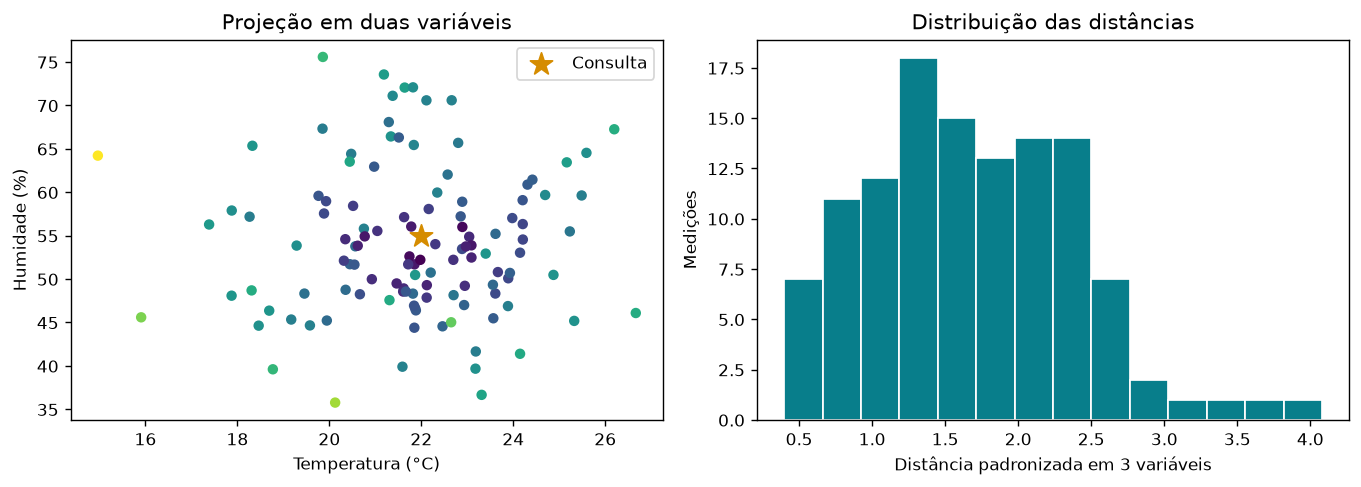

O gráfico da esquerda omite a pressão: proximidade visual em 2D não garante proximidade em 3D.


In [56]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].scatter(X_util[:, 0], X_util[:, 1], c=distancia_consulta, cmap="viridis", s=25)
eixos[0].scatter(medicao_consulta[0, 0], medicao_consulta[0, 1], marker="*", s=180, color="#d58c00", label="Consulta")
eixos[0].set(xlabel="Temperatura (°C)", ylabel="Humidade (%)", title="Projeção em duas variáveis")
eixos[0].legend()
eixos[1].hist(distancia_consulta, bins=14, color="#087e8b", edgecolor="white")
eixos[1].set(xlabel="Distância padronizada em 3 variáveis", ylabel="Medições", title="Distribuição das distâncias")
fig.tight_layout(); mostrar_figura(fig)
print("O gráfico da esquerda omite a pressão: proximidade visual em 2D não garante proximidade em 3D.")

In [57]:
np.savez_compressed(PASTA / "sensores_preparados.npz", ids=ids_util, X=X_util, Z=Z_projeto,
                    media=mu_projeto, escala=escala_projeto, colunas=nomes_variaveis)
metadados_projeto = {
    "origem": "Sintética; semente 301", "versoes": VERSOES,
    "linhas_brutas": int(len(X_bruto)), "linhas_utilizaveis": int(len(X_util)),
    "ids_excluidos": ids[~utilizavel].tolist(),
    "regra_exclusao": "Valores não finitos ou humidade fora de [0,100]",
    "ajuste_escala": "Primeiras 80 medições utilizáveis; ddof=0",
    "distancia": "Euclidiana após padronização; três variáveis com igual peso",
    "limites": "Dados sintéticos; sem modelo físico, temporal ou de correlações"
}
(PASTA / "sensores_metadados.json").write_text(json.dumps(metadados_projeto, ensure_ascii=False, indent=2), encoding="utf-8")
with np.load(PASTA / "sensores_preparados.npz", allow_pickle=False) as dados_guardados:
    np.testing.assert_array_equal(dados_guardados["ids"], ids_util)
    np.testing.assert_allclose(dados_guardados["Z"], Z_projeto)
print("Dados e metadados guardados e verificados.")

Dados e metadados guardados e verificados.


### Exercício 15

Adapta o miniprojeto a uma nova consulta `[25., 65., 1010.]`. Usa as mesmas médias e escalas. Identifica os três IDs mais próximos e explica por que não deves ajustar a escala usando apenas a nova consulta.

Resolve antes de consultar a solução comentada na parte final.

In [58]:
# Exercício 15 – escreve a tua resolução aqui.


## 22. Consulta rápida e erros frequentes
| Objetivo | Expressão |
|---|---|
| Criar | `np.array(...)`, `np.arange(...)`, `np.linspace(...)` |
| Inspecionar | `a.shape`, `a.ndim`, `a.dtype`, `a.size` |
| Selecionar bloco | `a[linhas, colunas]` |
| Preservar uma coluna 2D | `a[:, j:j+1]` |
| Novo eixo | `a[:, None]`, `a[None, :]` |
| Copiar | `a.copy()` |
| Verificar memória partilhada | `np.shares_memory(a, b)` |
| Reorganizar | `reshape`, `transpose`, `swapaxes` |
| Combinar | `concatenate`, `stack`, `column_stack` |
| Agregar | `sum`, `mean`, `std`, com `axis` e `keepdims` |
| Índice de um extremo | `argmin`, `argmax` |
| Filtrar | `a[mascara]` |
| Comparar | `array_equal` para igualdade; `allclose` para aproximação |
| Produto matricial | `@` |
| Resolver sistema quadrado | `np.linalg.solve(A, b)` |

**Erros a evitar:** confundir lista com array; interpretar `(n,)` como vetor coluna; trocar `*` e `@`; esquecer parênteses em máscaras; alterar uma vista inadvertidamente; reduzir o eixo errado; dividir por zero; truncar decimais com `astype(int)` sem intenção; escolher tipos demasiado pequenos; gerar temporários enormes; usar estatísticas do teste no treino.

**Checkpoint:** já consegues prever a forma de uma seleção, explicar os eixos reduzidos e justificar a comparação numérica utilizada? Se sim, podes avançar para o aprofundamento opcional. Caso contrário, resolve os exercícios 1–15 e consulta as soluções na Parte V.

# Parte IV – Aprofundamento opcional de álgebra linear
## 23. Quando aprofundar estes conceitos?
Esta parte ajuda a interpretar transformações, redundância de variáveis e sistemas de equações. Não é necessária para completar o miniprojeto.

| Conceito | Pergunta a que responde | Exemplo de utilização |
|---|---|---|
| Determinante | Qual a escala orientada de volume de uma transformação quadrada? | Geometria e invertibilidade em teoria |
| Posto | Quantas direções independentes existem? | Redundância e identificabilidade de incógnitas |
| Inversa | Que transformação desfaz a original? | Compreensão de transformações reversíveis |
| Valores próprios | Que direções são preservadas, apenas com mudança de escala? | Covariância, PCA e dinâmica linear |
| Condicionamento | Quão sensível é a solução a pequenas perturbações? | Avaliação de fiabilidade numérica |

O algoritmo escolhido, o tipo numérico e a escala dos dados influenciam os resultados. Não basta obter números sem verificar o significado.

### 23.1 Determinante em 2D

Para $A=\begin{bmatrix}a&b\\c&d\end{bmatrix}$:

$$\det(A)=ad-bc.$$

O módulo do determinante é o fator de escala da área; o sinal indica preservação ou inversão de orientação. Em matemática exata, uma matriz quadrada é invertível se e só se o determinante não for zero. Em ponto flutuante, **não uses apenas `det(A) == 0` para decidir singularidade**.

In [59]:
A_op = np.array([[4., 1.], [2., 3.]])
determinante_manual = 4 * 3 - 1 * 2
print("Manual:", determinante_manual)
print("NumPy:", np.linalg.det(A_op))
colapsada = np.array([[1., 2.], [2., 4.]])
print("Determinante da transformação que colapsa direções:", np.linalg.det(colapsada))
escala_pequena = 1e-10 * np.eye(2)
print("Determinante pequeno:", np.linalg.det(escala_pequena))
print("Condicionamento desta matriz:", np.linalg.cond(escala_pequena))
assert np.isclose(np.linalg.det(A_op), 10)

Manual: 10
NumPy: 10.000000000000002
Determinante da transformação que colapsa direções: 0.0
Determinante pequeno: 9.999999999999992e-21
Condicionamento desta matriz: 1.0


**Interpretação:** Uma matriz com determinante muito pequeno pode ser perfeitamente condicionada: `1e-10 * I` tem condicionamento 1. Se precisares do logaritmo de um determinante muito grande ou pequeno, estuda `np.linalg.slogdet` para reduzir problemas de overflow/underflow.

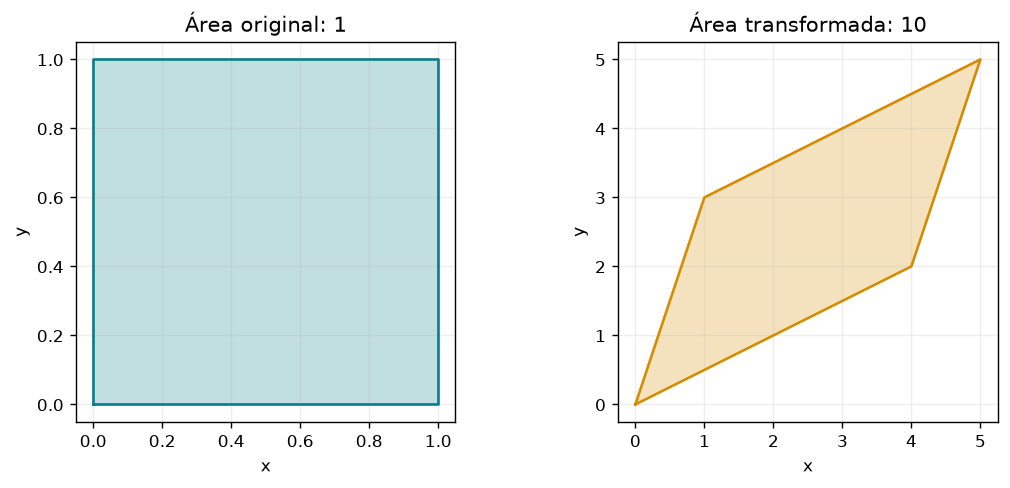

In [60]:
quadrado = np.array([[0., 0.], [1., 0.], [1., 1.], [0., 1.], [0., 0.]])
transformado = quadrado @ A_op.T
fig, eixos = plt.subplots(1, 2, figsize=(9, 4))
for ax, pontos, titulo, cor in [(eixos[0], quadrado, "Área original: 1", "#087e8b"),
                              (eixos[1], transformado, "Área transformada: 10", "#d58c00")]:
    ax.fill(pontos[:, 0], pontos[:, 1], color=cor, alpha=0.25)
    ax.plot(pontos[:, 0], pontos[:, 1], color=cor)
    ax.set_aspect("equal"); ax.set_title(titulo); ax.grid(alpha=0.2)
    ax.set(xlabel="x", ylabel="y")
fig.tight_layout(); mostrar_figura(fig)

### Exercício 16

Calcula à mão e com NumPy o determinante de `[[3, 1], [2, 2]]`. Compara com o de `[[3, 1], [6, 2]]`. Explica a diferença entre área preservada em duas dimensões e colapso numa direção.

Resolve antes de consultar a solução comentada na parte final.

In [61]:
# Exercício 16 – escreve a tua resolução aqui.


### 23.2 Posto e dependência linear

O posto é o número máximo de colunas linearmente independentes, igual ao número máximo de linhas independentes. NumPy estima o posto com base em valores singulares e numa tolerância; para dados quase dependentes, a escala e o limiar importam.

In [62]:
independente = np.array([[1., 0.], [0., 1.], [1., 1.]])
redundante = np.array([[1., 2., 3.], [2., 4., 6.], [3., 6., 9.]])
print("Forma independente:", independente.shape, "| posto:", np.linalg.matrix_rank(independente))
print("Forma redundante:", redundante.shape, "| posto:", np.linalg.matrix_rank(redundante))
quase = np.diag([1., 1e-12])
print("Posto por defeito:", np.linalg.matrix_rank(quase))
print("Posto com tol=1e-10:", np.linalg.matrix_rank(quase, tol=1e-10))
assert np.linalg.matrix_rank(redundante) == 1

Forma independente: (3, 2) | posto: 2
Forma redundante: (3, 3) | posto: 1
Posto por defeito: 2
Posto com tol=1e-10: 1


**Interpretação:** Na matriz redundante, as colunas são múltiplas umas das outras: a tabela tem três colunas mas só uma direção independente. Não confundas dependência linear com qualquer relação estatística ou causal.

### 23.3 Inversa: compreender e verificar

A inversa satisfaz $AA^{-1}=A^{-1}A=I$. Só uma matriz quadrada não singular tem inversa usual. A inversa permite desfazer uma transformação linear reversível, mas não é a ferramenta preferida para resolver $Ax=b$.

In [63]:
inversa_op = np.linalg.inv(A_op)
print("Inversa:\n", inversa_op)
print("A @ inversa:\n", A_op @ inversa_op)
np.testing.assert_allclose(A_op @ inversa_op, np.eye(2), atol=1e-12)
ponto_original = np.array([2., 1.])
ponto_transformado = A_op @ ponto_original
ponto_recuperado = inversa_op @ ponto_transformado
np.testing.assert_allclose(ponto_recuperado, ponto_original, atol=1e-12)
try:
    np.linalg.inv(colapsada)
except np.linalg.LinAlgError as erro:
    print("Inversa inexistente neste exemplo:", erro)

Inversa:
 [[ 0.3 -0.1]
 [-0.2  0.4]]
A @ inversa:
 [[ 1.  0.]
 [-0.  1.]]
Inversa inexistente neste exemplo: Singular matrix


**Interpretação:** Uma matriz mal condicionada pode produzir uma inversa numericamente pouco fiável sem lançar uma exceção. Verifica condicionamento e adequação ao problema; a ausência de erro não prova precisão.

### Exercício 17

Constrói uma matriz com uma coluna igual ao dobro de outra e verifica o posto. Escolhe outra matriz quadrada invertível, calcula a inversa apenas para demonstração e confirma os produtos com a identidade usando tolerância explícita.

Resolve antes de consultar a solução comentada na parte final.

In [64]:
# Exercício 17 – escreve a tua resolução aqui.


### 23.4 Resolver sistemas: privilegiar solve

Considera o sistema:

$$\begin{cases}4x+y=9\\2x+3y=7\end{cases}\quad\Longleftrightarrow\quad A x=b.$$

A solução é $x=2$ e $y=1$. Usa `solve(A, b)` para resolver diretamente: evita construir e armazenar uma inversa que não é necessária e tende a ser mais eficiente e numericamente mais fiável. Não é uma garantia de que `inv(A) @ b` vá falhar em todos os casos; no exemplo simples, os resultados coincidem.

In [65]:
b_op = np.array([9., 7.])
x_solve = np.linalg.solve(A_op, b_op)
x_via_inversa = np.linalg.inv(A_op) @ b_op  # Apenas comparação didática.
print("solve:", x_solve)
print("inv @ b:", x_via_inversa)
print("Resíduo:", A_op @ x_solve - b_op)
np.testing.assert_allclose(x_solve, [2., 1.], atol=1e-12)
np.testing.assert_allclose(A_op @ x_solve, b_op, atol=1e-12)
# Vários termos independentes: cada coluna de B define um sistema.
B_op = np.column_stack([b_op, 2 * b_op])
X_sistemas = np.linalg.solve(A_op, B_op)
print("Dois sistemas em simultâneo:\n", X_sistemas)
assert X_sistemas.shape == (2, 2)
np.testing.assert_allclose(A_op @ X_sistemas, B_op, atol=1e-12)

solve: [2. 1.]
inv @ b: [2. 1.]
Resíduo: [0. 0.]
Dois sistemas em simultâneo:
 [[2. 4.]
 [1. 2.]]


**Interpretação:** Para este uso, `A` deve ser quadrada e de posto completo. Mantém uma convenção clara para `b`: vetor `(n,)` para um sistema, matriz `(n,k)` para k termos independentes. As verificações numéricas devem usar tolerâncias coerentes com a escala.

### 23.5 Sistemas singulares e mínimos quadrados

Se há mais equações do que incógnitas, os dados podem não admitir uma solução exata. `np.linalg.lstsq` procura minimizar $\lVert Ax-b\rVert_2$; se houver várias soluções minimizadoras, devolve a de menor norma euclidiana.

Este princípio também é útil no ajuste de uma reta $y=\beta_0+\beta_1t$ a medições com ruído. Não vamos formar as equações normais $(A^TA)x=A^Tb$, que podem agravar o condicionamento.

In [66]:
A_singular = np.array([[1., 2.], [2., 4.]])
b_incompativel = np.array([3., 7.])
try:
    np.linalg.solve(A_singular, b_incompativel)
except np.linalg.LinAlgError as erro:
    print("solve rejeitou o sistema singular:", erro)
x_min, residuos_api, posto_api, valores_singulares = np.linalg.lstsq(A_singular, b_incompativel, rcond=None)
print("Mínimos quadrados no sistema incompatível:", x_min)
print("Resíduo calculado:", A_singular @ x_min - b_incompativel)
print("Posto:", posto_api, "| campo residual da API:", residuos_api)
# O campo residual pode estar vazio em problemas de posto deficiente.
print("Soma de quadrados residual explícita:", np.sum((A_singular @ x_min - b_incompativel)**2))

t = np.array([0., 1., 2., 3., 4.])
y_observado = np.array([1.1, 2.9, 5.2, 6.8, 9.1])
A_reta = np.column_stack([np.ones_like(t), t])
beta, residuos_reta, posto_reta, _ = np.linalg.lstsq(A_reta, y_observado, rcond=None)
y_ajustado = A_reta @ beta
print("Ordenada na origem e declive:", beta)
print("Posto:", posto_reta, "| soma quadrados:", np.sum((y_ajustado-y_observado)**2))
# A ortogonalidade do resíduo às colunas é uma verificação do ajuste.
np.testing.assert_allclose(A_reta.T @ (y_ajustado - y_observado), 0, atol=1e-10)

solve rejeitou o sistema singular: Singular matrix
Mínimos quadrados no sistema incompatível: [0.68 1.36]
Resíduo calculado: [ 0.4 -0.2]
Posto: 1 | campo residual da API: []
Soma de quadrados residual explícita: 0.2
Ordenada na origem e declive: [1.04 1.99]
Posto: 2 | soma quadrados: 0.10700000000000001


**Interpretação:** Para um sistema consistente mas sem solução única, `solve` também não é adequado. `lstsq` permite obter uma solução de menor norma. Um bom ajuste numérico não substitui a análise dos pressupostos ou a avaliação em dados novos.

### Exercício 18

Resolve `5x + y = 11` e `2x + 3y = 7` com `solve`. Depois ajusta uma reta aos pontos `t=[0,1,2,3]`, `y=[2.1,3.8,6.2,7.9]` com `lstsq`, sem calcular inversas nem formar equações normais. Mostra os resíduos.

Resolve antes de consultar a solução comentada na parte final.

In [67]:
# Exercício 18 – escreve a tua resolução aqui.


### 23.6 Condicionamento e sensibilidade

Um problema mal condicionado amplifica pequenas alterações nos dados. `np.linalg.cond` com o padrão de norma 2 estima a razão entre o maior e o menor valor singular. Não existe um limite universal de condicionamento aceitável: depende da precisão, das unidades e da exatidão exigida.

Um **resíduo pequeno** mostra que a solução satisfaz aproximadamente as equações fornecidas; não garante que esteja próxima da solução do problema original quando os dados são incertos.

In [68]:
epsilon = 1e-8
A_sensivel = np.array([[1., 1.], [1., 1. + epsilon]])
x_exato = np.array([1., 1.])
b_exato = A_sensivel @ x_exato
b_perturbado = b_exato + np.array([0., 1e-7])
x_perturbado = np.linalg.solve(A_sensivel, b_perturbado)
perturbacao_relativa = np.linalg.norm(b_perturbado-b_exato) / np.linalg.norm(b_exato)
erro_relativo = np.linalg.norm(x_perturbado-x_exato) / np.linalg.norm(x_exato)
residuo_relativo = np.linalg.norm(A_sensivel @ x_perturbado-b_perturbado) / np.linalg.norm(b_perturbado)
print("Condicionamento:", np.linalg.cond(A_sensivel))
print("Perturbação relativa de b:", perturbacao_relativa)
print("Solução obtida:", x_perturbado)
print("Erro relativo em relação à solução original:", erro_relativo)
print("Resíduo relativo das equações perturbadas:", residuo_relativo)
assert erro_relativo > 1
assert perturbacao_relativa < 1e-6

Condicionamento: 400000006.23500437
Perturbação relativa de b: 3.535533891307723e-08
Solução obtida: [-9. 11.]
Erro relativo em relação à solução original: 10.000000044408921
Resíduo relativo das equações perturbadas: 1.570092415506233e-16


**Interpretação:** O algoritmo resolve as equações perturbadas, mas a solução mudou muito. Calcular a inversa não resolve o mau condicionamento. Pode ser necessário rever variáveis, escalas, medições ou a formulação do problema.

### Exercício 19

Compara `cond(I)` com `cond(A_sensivel)`. Repete a perturbação de `b` com amplitude `1e-9` e interpreta a relação entre alteração dos dados, alteração da solução e resíduo.

Resolve antes de consultar a solução comentada na parte final.

In [69]:
# Exercício 19 – escreve a tua resolução aqui.


### 23.7 Valores e vetores próprios

Um vetor próprio não nulo $v$ satisfaz:

$$Av=\lambda v.$$

A transformação preserva essa direção, podendo mudar comprimento e sentido. $\lambda$ é o valor próprio correspondente. As colunas da matriz devolvida por `eig` ou `eigh` são os vetores próprios.

Usa `eigh` quando a matriz é real simétrica, ou complexa hermitiana. Usa `eig` para uma matriz geral, que pode ter valores e vetores próprios complexos mesmo com entradas reais.

In [70]:
A_simetrica = np.array([[3., 1.], [1., 3.]])
valores, vetores = np.linalg.eigh(A_simetrica)
print("Valores próprios:", valores)
print("Vetores próprios nas colunas:\n", vetores)
for j in range(len(valores)):
    np.testing.assert_allclose(A_simetrica @ vetores[:, j], valores[j] * vetores[:, j], atol=1e-12)
np.testing.assert_allclose(vetores.T @ vetores, np.eye(2), atol=1e-12)
# Exemplo geral: rotação de 90 graus não tem direções próprias reais.
rotacao = np.array([[0., -1.], [1., 0.]])
valores_complexos, vetores_complexos = np.linalg.eig(rotacao)
print("Valores próprios da rotação:", valores_complexos)
np.testing.assert_allclose(rotacao @ vetores_complexos,
                           vetores_complexos * valores_complexos, atol=1e-12)

Valores próprios: [2. 4.]
Vetores próprios nas colunas:
 [[-0.7071  0.7071]
 [ 0.7071  0.7071]]
Valores próprios da rotação: [0.+1.j 0.-1.j]


**Interpretação:** O sinal de um vetor próprio pode mudar sem alterar a sua validade; a ordem também depende da função. Com valores próprios repetidos, diferentes bases do mesmo subespaço podem ser corretas. Verifica a relação matemática, em vez de exigir vetores com uma forma textual fixa.

### 23.8 Quando fazem sentido: direções de variabilidade

Numa matriz de covariância, os vetores próprios identificam direções de variabilidade e os valores próprios quantificam a variância nessas direções. É a ideia central de PCA. O exemplo seguinte ilustra apenas a decomposição, sem construir uma avaliação preditiva.

Covariância:
 [[1.0059 1.5167]
 [1.5167 2.3782]]
Variâncias das componentes: [3.3567 0.0274]
Proporção explicada: [0.9919 0.0081]


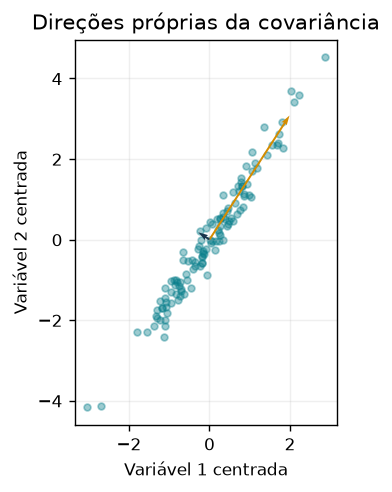

In [71]:
rng_pca = np.random.default_rng(50)
a_pca = rng_pca.normal(0, 1, 120)
X_pca = np.column_stack([a_pca, 1.5 * a_pca + rng_pca.normal(0, 0.3, 120)])
centrados_pca = X_pca - X_pca.mean(axis=0, keepdims=True)
covariancia = centrados_pca.T @ centrados_pca / (len(X_pca) - 1)
vp, direcoes = np.linalg.eigh(covariancia)
ordem_pca = np.argsort(vp)[::-1]
vp, direcoes = vp[ordem_pca], direcoes[:, ordem_pca]
print("Covariância:\n", covariancia)
print("Variâncias das componentes:", vp)
print("Proporção explicada:", vp / vp.sum())
projecao_1d = centrados_pca @ direcoes[:, :1]
assert projecao_1d.shape == (len(X_pca), 1)
np.testing.assert_allclose(np.var(projecao_1d[:, 0], ddof=1), vp[0], atol=1e-12)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(centrados_pca[:, 0], centrados_pca[:, 1], alpha=0.4, s=15, color="#087e8b")
for j, cor in [(0, "#d58c00"), (1, "#18344c")]:
    seta = direcoes[:, j] * np.sqrt(vp[j]) * 2
    ax.quiver(0, 0, seta[0], seta[1], angles="xy", scale_units="xy", scale=1, color=cor)
ax.set(xlabel="Variável 1 centrada", ylabel="Variável 2 centrada", title="Direções próprias da covariância")
ax.set_aspect("equal"); ax.grid(alpha=0.2); mostrar_figura(fig)

**Interpretação:** PCA depende das escalas das variáveis: centrar não é o mesmo que padronizar. Conservar uma componente descarta informação das outras direções. Para uso preditivo, estima centragens, escalas e direções apenas no treino.

### Exercício 20

Usa `eigh` em `[[4., 2.], [2., 4.]]`. Verifica `A @ v = lambda * v` para cada coluna e a ortonormalidade. Explica a diferença entre o vetor próprio e o seu valor próprio.

Resolve antes de consultar a solução comentada na parte final.

In [72]:
# Exercício 20 – escreve a tua resolução aqui.


# Parte V – Soluções, verificações e referências
## Soluções comentadas
As soluções são uma possibilidade, não a única. Compara o significado dos resultados e as dimensões, além do código.

### Exercícios 1–3 – Matemática, criação e seleção

In [73]:
# 1 – Soma e produto elemento a elemento são vetores; produto escalar e distância são escalares.
p_ex1 = np.array([3, -2]); q_ex1 = np.array([1, 4])
print("Soma:", p_ex1 + q_ex1)
print("Produto elemento a elemento:", p_ex1 * q_ex1)
print("Produto escalar:", p_ex1 @ q_ex1)
print("Distância:", np.linalg.norm(p_ex1 - q_ex1))
assert p_ex1 @ q_ex1 == -5
np.testing.assert_allclose(np.linalg.norm(p_ex1-q_ex1), np.sqrt(40))

# 2 – 36 elementos: 3 * 4 * 3.
ex2 = np.arange(10, 46, dtype=np.int32).reshape(3, 4, 3)
print("Ex2:", ex2.shape, ex2.ndim, ex2.size, ex2.itemsize, ex2.nbytes)
assert ex2.size == 36 and ex2.nbytes == 144

# 3 – Fim do slice excluído; intervalo de uma coluna conserva o eixo.
ex3 = np.arange(30).reshape(5, 6)
print("Bloco:\n", ex3[1:4, 2:5])
print("Última coluna 2D:\n", ex3[:, -1:])
print("Linhas invertidas:\n", ex3[::-1, :])
assert ex3[1:4, 2:5].shape == (3, 3)
assert ex3[:, -1:].shape == (5, 1)

Soma: [4 2]
Produto elemento a elemento: [ 3 -8]
Produto escalar: -5
Distância: 6.324555320336759
Ex2: (3, 4, 3) 3 36 4 144
Bloco:
 [[ 8  9 10]
 [14 15 16]
 [20 21 22]]
Última coluna 2D:
 [[ 5]
 [11]
 [17]
 [23]
 [29]]
Linhas invertidas:
 [[24 25 26 27 28 29]
 [18 19 20 21 22 23]
 [12 13 14 15 16 17]
 [ 6  7  8  9 10 11]
 [ 0  1  2  3  4  5]]


### Exercícios 4–6 – Máscaras, memória e formas

In [74]:
# 4 – Copiar antes de corrigir permite preservar a entrada.
ex4 = np.array([[2, -3, 8], [11, 4, -1]])
ex4_original = ex4.copy()
print("Negativos:", np.count_nonzero(ex4 < 0))
print("Coordenadas:\n", np.argwhere(ex4 < 0))
ex4_limpo = np.clip(ex4.copy(), 0, 10)
print(ex4_limpo)
np.testing.assert_array_equal(ex4, ex4_original)
assert ((ex4_limpo >= 0) & (ex4_limpo <= 10)).all()

# 5 – A vista altera o original; a cópia tem dados independentes.
ex5 = np.arange(6)
ex5_vista = ex5[:3]
ex5_vista[0] = 77
assert np.shares_memory(ex5, ex5_vista) and ex5[0] == 77
ex5_copia = ex5[:3].copy()
ex5_copia[1] = 88
assert not np.shares_memory(ex5, ex5_copia) and ex5[1] == 1
print("Origem:", ex5, "| cópia:", ex5_copia)

# 6 – Só stack cria um eixo novo.
ex6_a = np.arange(8).reshape(2, 4)
ex6_b = np.arange(20, 28).reshape(2, 4)
ex6_vertical = np.concatenate([ex6_a, ex6_b], axis=0)
ex6_horizontal = np.concatenate([ex6_a, ex6_b], axis=1)
ex6_lotes = np.stack([ex6_a, ex6_b], axis=0)
print("Formas:", ex6_vertical.shape, ex6_horizontal.shape, ex6_lotes.shape)
assert ex6_vertical.shape == (4,4) and ex6_horizontal.shape == (2,8) and ex6_lotes.shape == (2,2,4)

Negativos: 2
Coordenadas:
 [[0 1]
 [1 2]]
[[ 2  0  8]
 [10  4  0]]
Origem: [77  1  2  3  4  5] | cópia: [77 88  2]
Formas: (4, 4) (2, 8) (2, 2, 4)


### Exercícios 7–9 – Broadcasting, eixos e aleatoriedade

In [75]:
# 7 – O vetor de colunas alinha no último eixo; fatores de linhas precisam de (4,1).
ex7 = np.arange(12).reshape(4, 3)
ex7_por_coluna = np.array([10, 20, 30])
ex7_fatores = np.array([1, 2, 3, 4])[:, None]
print("Formas:", ex7.shape, ex7_por_coluna.shape, ex7_fatores.shape)
print("Soma:\n", ex7 + ex7_por_coluna)
print("Multiplicação:\n", ex7 * ex7_fatores)

# 8 – Reduzir eixo 0 produz uma média por variável.
ex8 = np.arange(12, dtype=float).reshape(4, 3)
print("Média por variável:", ex8.mean(axis=0))
print("Soma por observação:", ex8.sum(axis=1))
ex8_media = ex8.mean(axis=0, keepdims=True)
ex8_centrado = ex8 - ex8_media
assert ex8_media.shape == (1, 3)
np.testing.assert_allclose(ex8_centrado.mean(axis=0), 0, atol=1e-12)

# 9 – Parâmetros da distribuição não são estatísticas exatas de uma amostra finita.
ex9 = np.random.default_rng(15).normal(10, 2, 1000)
ex9_repetido = np.random.default_rng(15).normal(10, 2, 1000)
print("Média observada:", ex9.mean(), "| desvio observado:", ex9.std(ddof=0))
np.testing.assert_array_equal(ex9, ex9_repetido)

Formas: (4, 3) (3,) (4, 1)
Soma:
 [[10 21 32]
 [13 24 35]
 [16 27 38]
 [19 30 41]]
Multiplicação:
 [[ 0  1  2]
 [ 6  8 10]
 [18 21 24]
 [36 40 44]]
Média por variável: [4.5 5.5 6.5]
Soma por observação: [ 3. 12. 21. 30.]
Média observada: 10.029631750651927 | desvio observado: 1.9231809116650527


### Exercícios 10–12 – Valores especiais, sistemas e padronização

In [76]:
# 10 – A média dos três finitos é (4+10-2)/3 = 4.
ex10 = np.array([4., np.nan, 10., np.inf, -2.])
ex10_mascara = np.isfinite(ex10)
print("Máscara:", ex10_mascara, "| excluídos:", (~ex10_mascara).sum())
print("Média válida:", ex10[ex10_mascara].mean())
ex10_n = np.array([3., 4.]); ex10_d = np.array([0., 2.])
ex10_q = np.full_like(ex10_n, np.nan)
np.divide(ex10_n, ex10_d, out=ex10_q, where=ex10_d != 0)
assert np.isnan(ex10_q[0]) and ex10_q[1] == 2

# 11 – Resolver diretamente, sem construir a inversa.
ex11_A = np.array([[3., 1.], [1., 2.]])
ex11_b = np.array([9., 8.])
ex11_x = np.linalg.solve(ex11_A, ex11_b)
print("Solução:", ex11_x, "| norma do resíduo:", np.linalg.norm(ex11_A @ ex11_x-ex11_b))
np.testing.assert_allclose(ex11_x, [2., 3.], atol=1e-12)

# 12 – A constante transforma-se em zeros e conserva desvio zero.
ex12 = np.array([[2., 10., 5.], [4., 20., 5.], [6., 40., 5.], [8., 50., 5.]])
ex12_mu, ex12_escala = ajustar_padronizacao(ex12)
ex12_z = aplicar_padronizacao(ex12, ex12_mu, ex12_escala)
np.testing.assert_allclose(ex12_z.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(ex12_z.std(axis=0), [1,1,0], atol=1e-12)
print("Nova linha transformada:", aplicar_padronizacao(np.array([[10., 60., 5.]]), ex12_mu, ex12_escala))

Máscara: [ True False  True False  True] | excluídos: 2
Média válida: 4.0
Solução: [2. 3.] | norma do resíduo: 0.0
Nova linha transformada: [[2.2361 1.8974 0.    ]]


### Exercícios 13–15 – Comparação, ficheiros e projeto

In [77]:
# 13 – Mascarar a diagonal evita escolher o próprio ponto como vizinho.
ex13 = np.array([[0., 0.], [1., 0.], [0., 3.]])
ex13_D = np.linalg.norm(ex13[:, None, :] - ex13[None, :, :], axis=2)
np.testing.assert_allclose(ex13_D, ex13_D.T, atol=1e-12)
np.testing.assert_allclose(np.diag(ex13_D), 0, atol=1e-12)
ex13_sem_proprio = ex13_D.copy()
np.fill_diagonal(ex13_sem_proprio, np.inf)
print("Vizinhos mais próximos:", ex13_sem_proprio.argmin(axis=1))
ex13_C = matriz_cosseno(np.array([[1., 0.], [0., 0.]]))
assert np.isnan(ex13_C[1]).all()

# 14 – Arrays textuais NumPy podem ser guardados sem pickle.
ex14 = np.arange(12, dtype=np.float32).reshape(3, 4)
ex14_colunas = np.array(["a", "b", "c", "d"])
np.save(PASTA / "exercicio14.npy", ex14)
ex14_lido = np.load(PASTA / "exercicio14.npy", allow_pickle=False)
np.testing.assert_array_equal(ex14_lido, ex14)
assert ex14_lido.dtype == np.float32 and ex14_lido.shape == (3,4)
np.savez_compressed(PASTA / "exercicio14.npz", X=ex14, colunas=ex14_colunas)
with np.load(PASTA / "exercicio14.npz", allow_pickle=False) as ex14_npz:
    np.testing.assert_array_equal(ex14_npz["colunas"], ex14_colunas)

# 15 – Mesma transformação, nova consulta.
ex15_consulta = np.array([[25., 65., 1010.]])
ex15_z = aplicar_padronizacao(ex15_consulta, mu_projeto, escala_projeto)
ex15_distancias = np.linalg.norm(Z_projeto - ex15_z, axis=1)
ex15_top = np.argsort(ex15_distancias)[:3]
print("IDs:", ids_util[ex15_top], "| distâncias:", ex15_distancias[ex15_top])
# Ajustar a escala só numa linha daria desvios zero e perderia a referência de comparação.

Vizinhos mais próximos: [1 0 0]
IDs: [ 28 114  93] | distâncias: [0.6714 0.7144 0.7681]


### Exercícios 16–17 – Determinante, posto e inversa (opcionais)

In [78]:
# 16 – Determinante 4 corresponde a área multiplicada por 4; determinante zero colapsa a área.
ex16_A = np.array([[3., 1.], [2., 2.]])
ex16_B = np.array([[3., 1.], [6., 2.]])
print("Determinantes:", np.linalg.det(ex16_A), np.linalg.det(ex16_B))
assert np.isclose(np.linalg.det(ex16_A), 4.)
assert np.linalg.matrix_rank(ex16_B) == 1

# 17 – Posto deteta redundância; a inversa é aqui uma demonstração de reversibilidade.
ex17_redundante = np.array([[1., 2.], [3., 6.], [5., 10.]])
assert np.linalg.matrix_rank(ex17_redundante) == 1
ex17_A = np.array([[2., 1.], [0., 3.]])
ex17_inversa = np.linalg.inv(ex17_A)
np.testing.assert_allclose(ex17_A @ ex17_inversa, np.eye(2), atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(ex17_inversa @ ex17_A, np.eye(2), atol=1e-12, rtol=1e-12)
print("Inversa verificada nos dois sentidos.")

Determinantes: 4.000000000000001 0.0
Inversa verificada nos dois sentidos.


### Exercícios 18–20 – Sistemas, condicionamento e valores próprios (opcionais)

In [79]:
# 18 – solve para sistema quadrado; lstsq para ajuste com mais equações que incógnitas.
ex18_A = np.array([[5., 1.], [2., 3.]])
ex18_b = np.array([11., 7.])
ex18_x = np.linalg.solve(ex18_A, ex18_b)
np.testing.assert_allclose(ex18_x, [2.,1.], atol=1e-12)
ex18_t = np.array([0.,1.,2.,3.])
ex18_y = np.array([2.1,3.8,6.2,7.9])
ex18_design = np.column_stack([np.ones_like(ex18_t), ex18_t])
ex18_beta, _, _, _ = np.linalg.lstsq(ex18_design, ex18_y, rcond=None)
print("Solução do sistema:", ex18_x)
print("Parâmetros da reta:", ex18_beta)
print("Resíduos da reta:", ex18_design @ ex18_beta-ex18_y)

# 19 – A sensibilidade pertence ao problema, não desaparece por usar solve.
print("cond(I):", np.linalg.cond(np.eye(2)))
print("cond(A_sensivel):", np.linalg.cond(A_sensivel))
ex19_b = b_exato + np.array([0.,1e-9])
ex19_x = np.linalg.solve(A_sensivel, ex19_b)
print("Nova solução:", ex19_x)
print("Alteração na solução:", ex19_x-x_exato)
print("Resíduo:", A_sensivel @ ex19_x-ex19_b)
# Uma perturbação menor reduz a alteração, mas a amplificação continua elevada.

# 20 – Cada coluna de V corresponde a um valor próprio.
ex20_A = np.array([[4.,2.],[2.,4.]])
ex20_valores, ex20_vetores = np.linalg.eigh(ex20_A)
np.testing.assert_allclose(ex20_valores, [2.,6.], atol=1e-12)
np.testing.assert_allclose(ex20_A @ ex20_vetores, ex20_vetores * ex20_valores, atol=1e-12)
np.testing.assert_allclose(ex20_vetores.T @ ex20_vetores, np.eye(2), atol=1e-12)
print("Valores:", ex20_valores, "| vetores nas colunas:\n", ex20_vetores)
# Vetor próprio: direção não nula; valor próprio: fator de escala nessa direção.

Solução do sistema: [2. 1.]
Parâmetros da reta: [2.03 1.98]
Resíduos da reta: [-0.07  0.21 -0.21  0.07]
cond(I): 1.0
cond(A_sensivel): 400000006.23500437
Nova solução: [0.9 1.1]
Alteração na solução: [-0.1  0.1]
Resíduo: [0. 0.]
Valores: [2. 6.] | vetores nas colunas:
 [[-0.7071  0.7071]
 [ 0.7071  0.7071]]


## Verificações finais e limites
Além das verificações junto dos exemplos, testamos o tratamento de entradas inválidas nas funções de preparação e a política para vetores nulos. Falhas esperadas são capturadas; uma falha inesperada interrompe a execução.

In [80]:
# Contratos de entrada das funções: evitar resultados silenciosamente incorretos.
for entrada_invalida in [np.array([1.,2.]), np.array([[1.,np.nan]]), np.empty((0,2))]:
    try:
        ajustar_padronizacao(entrada_invalida)
    except ValueError:
        pass
    else:
        raise AssertionError("Uma entrada inválida foi aceite.")
try:
    aplicar_padronizacao(np.ones((2,4)), np.ones((1,3)), np.ones((1,3)))
except ValueError:
    pass
else:
    raise AssertionError("Deveria ter sido detetada incompatibilidade de formas.")
assert np.isnan(matriz_cosseno(np.zeros((1,2)))).all()
np.testing.assert_allclose(aplicar_padronizacao(X_preparar, mu_treino, escala_treino).mean(axis=0), 0, atol=1e-12)
print("Verificações finais concluídas.")
(PASTA / "versoes.json").write_text(json.dumps(VERSOES, indent=2), encoding="utf-8")
print("Ficheiros produzidos:", sorted(p.name for p in PASTA.iterdir()))

Verificações finais concluídas.
Ficheiros produzidos: ['conjunto.npz', 'exercicio14.npy', 'exercicio14.npz', 'matriz.csv', 'matriz.npy', 'sensores_metadados.json', 'sensores_preparados.npz', 'versoes.json']


## Plano de estudo e autoavaliação
| Sessão | Conteúdos | Evidência de aprendizagem |
|---|---|---|
| 1 | Preparação e revisão matemática | Distinguir `*` e `@`, prever dimensões |
| 2 | Criação, tipos e seleção | Extrair blocos e preservar eixos |
| 3 | Memória, reshape e broadcasting | Explicar mutações e compatibilidades |
| 4 | Eixos, estatística e aleatoriedade | Agregar no eixo adequado e reproduzir amostras |
| 5 | Preparação, distâncias e ficheiros | Tratar constantes e verificar exportações |
| 6 | Miniprojeto | Justificar escalas, exclusões e interpretação |
| Opcional | Álgebra linear aprofundada | Escolher solve/lstsq e interpretar condicionamento |

Avalia de 0 a 2 cada competência: criação e tipos; indexação; memória; formas; broadcasting; eixos; cálculo numérico; preparação; ficheiros; interpretação do projeto. **Total: 20 pontos.** A secção opcional permite aprofundar sem penalizar o percurso principal.

### Limites e próximos passos
Este tutorial não substitui uma disciplina de álgebra linear ou estatística. Os exemplos com dados sintéticos são pedagógicos, não evidência de desempenho em dados reais. Para continuar, estuda álgebra linear numérica, SciPy, preparação de dados com Pandas e pipelines de aprendizagem automática. `einsum`, decomposição SVD aprofundada e cálculo fora de memória podem ser temas de um módulo posterior.

### Referências oficiais
- [NumPy – fundamentos para principiantes](https://numpy.org/doc/stable/user/absolute_beginners.html)
- [NumPy – quickstart](https://numpy.org/doc/stable/user/quickstart.html)
- [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)
- [Cópias e vistas](https://numpy.org/doc/stable/user/basics.copies.html)
- [Indexação](https://numpy.org/doc/stable/user/basics.indexing.html)
- [Comparações aproximadas](https://numpy.org/doc/stable/reference/generated/numpy.allclose.html)
- [Desvio padrão e ddof](https://numpy.org/doc/stable/reference/generated/numpy.std.html)
- [Geração aleatória](https://numpy.org/doc/stable/reference/random/generator.html)
- [Álgebra linear](https://numpy.org/doc/stable/reference/routines.linalg.html)
- [Resolver sistemas com solve](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html)
- [Mínimos quadrados com lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
- [Valores próprios de matrizes simétricas](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html)

Os links servem para aprofundamento; o percurso executável não precisa de os abrir.